# Comparative Evaluation of MLP and CNN Models for Blood Cell Classification. 

# From MLP to CNN: Spatial Feature Learning and Classifier-Head Efficiency on BloodMNIST

*A Study of Biomedical Image Classification*

**Author:** Victoria Tran (My-Uyen Tran)  

**Notebook:** `bloodmnist-mlp-cnn-uyentran.ipynb`

## Overview

This project presents a controlled educational comparison of multilayer perceptron (MLP) and convolutional neural network (CNN) architectures for eight-class blood cell image classification using the BloodMNIST dataset.

The study examines how convolutional feature extraction and classifier-head design relate to classification performance and parameter efficiency under a shared training protocol.

Three models are trained and evaluated: an MLP baseline (M0), a CNN with a Flatten classifier head (M1), and a CNN with Global Average Pooling (M2).

## Research Questions

1. **MLP vs. CNN:** How do MLP and CNN architectures compare in classification performance on BloodMNIST under the same official data splits and shared training settings?

2. **Flatten vs. Global Average Pooling:** How does replacing a Flatten classifier head with Global Average Pooling (GAP) affect the number of trainable parameters and classification performance when using the same CNN feature-extractor architecture?

## Experimental Design

Three models are evaluated:

| Model | Architecture | Role |
|---|---|---|
| **M0** | MLP with two hidden layers (256 → 128), ReLU and Dropout, without BatchNorm | Non-convolutional baseline |
| **M1** | Two-block CNN + BatchNorm + Flatten + Dropout + Linear | CNN baseline with a Flatten classifier head |
| **M2** | Two-block CNN + BatchNorm + GAP + Flatten + Dropout + Linear | Comparison of GAP versus Flatten |

M1 and M2 use the same two-block CNN feature-extractor architecture, with 32 and 64 output channels. Each block follows the sequence Conv2d → BatchNorm2d → ReLU → MaxPool2d.

M1 and M2 differ in their classifier heads and are initialized and trained independently. All three models use ReLU, Dropout (p = 0.2), and He/Kaiming Uniform initialization for the specified hidden Linear or convolutional weights.

Batch Normalization and Dropout are included as architectural components, not as separate ablation experiments.

## Model Architecture Overview

The diagram below illustrates the three model architectures, intermediate tensor shapes, weight initialization policies, and trainable parameter counts.  


![BloodMNIST Model Architecture Comparison](../figures/BloodMNIST%20Model%20Architectures%20Infographic.png)

Each model receives RGB images with input shape `(B, 3, 28, 28)` and produces eight raw classification logits with output shape `(B, 8)`, where `B` is the batch size.

The architectures have the following trainable parameter counts:

- **M0:** 636,296 parameters.  

- **M1:** 44,680 parameters.  

- **M2:** 20,104 parameters.

M2 has 24,576 fewer trainable parameters than M1, representing approximately a 55.0% reduction. This architectural difference will be examined alongside their classification performance.

## Experimental Protocol & Evaluation

- **Dataset:** BloodMNIST — 17,092 RGB images (28 × 28), eight classes, using the official splits: 11,959 training, 1,712 validation, and 3,421 test images.  

- **Preprocessing:** `transforms.ToTensor()` followed by training-derived RGB normalization for all three official splits, without data augmentation. 

- **Training:** Adam optimizer, learning rate 0.001, batch size 128, and unweighted cross-entropy loss.  

- **Reproducibility:** One predefined random seed (42), reset before independently initializing and training each model.  

- **Training duration:** 12 fixed epochs per model, without early stopping.  

- **Model selection:** Save the best checkpoint for each model based on validation macro-F1. Ties retain the earlier checkpoint.  

- **Validation metrics:** Loss, accuracy, and macro-F1 after every epoch.  

- **Final test metrics:** Macro-F1 (primary) and accuracy (secondary).  

- **Error analysis:** One confusion matrix for the predefined M2 model.  

- **Training outputs:** Model checkpoints, training histories, learning curves, and validation/test summary tables.

All three models are trained independently using the same experimental settings. The official test set is reserved for final evaluation after checkpoint selection.

Because this study uses a single random seed and a fixed training configuration, the results are interpreted as an educational architectural comparison rather than evidence of statistically significant or universally superior performance.

## Notebook Organization

- **Part 0:** Setup & Fixed Settings  

- **Part 1:** Load, Inspect & Normalize BloodMNIST  

- **Part 2:** Define M0, M1, M2 & Initialize Weights 

- **Part 3:** Basic Training & Validation  

- **Part 4:** Official Training: Only Three Runs 

- **Part 5:** Final Test Evaluation & Simple Error Analysis  

- **Part 6:** Results, Discussion & Conclusion

---



## Part 0 — Setup & Reproducibility

### Overview & Objective

Import the required libraries, define a single experiment configuration, and initialize the random seed and computation device.

### Workflow & Section Guide

- **0.1** Import libraries.
- **0.2** Define the `Config` dataclass.
- **0.3** Configure random seeds, device selection, and environment information.

### Important Objects & Their Roles

- `Config` / `cfg`: experiment settings shared across all models.
- `set_seed()`: initializes random-number generators for a run.
- `device`: selects CUDA, MPS, or CPU.

### Connections to Subsequent Parts

Parts 1–8 reuse `cfg`, `set_seed`, and `device`. The primary learning rate is **not** finalized until the pilot in Part 5.

### Expected Outcome & Role in the Experiment

A clear, consistent set of configuration values and a reproducible starting point for the experiments.

---

### 0.1 — Imports & Device Selection

**Objective:** Import the required Python libraries and select the appropriate PyTorch computation device for model training and evaluation.

**Procedure:**
1. Import the libraries needed for numerical operations, data analysis, visualization, MLP/CNN construction, training, and evaluation.
2. Select CUDA if available, otherwise Apple Silicon MPS if available, or CPU as a fallback.
3. Display the selected computation device.

**Expected Output:**
- All required libraries are successfully imported.
- The selected computation device (`cuda`, `mps`, or `cpu`) is displayed.



In [ ]:
%pip install torch torchvision medmnist scikit-learn matplotlib pandas numpy

# Import standard Python tools for reproducibility and file management.
import random                         
from pathlib import Path             
import sys  
print(sys.executable)
import time
from dataclasses import dataclass, field  
import math
import json  

# Import libraries for numerical analysis, data tables, and visualization.
import numpy as np                    
import pandas as pd                   
import matplotlib.pyplot as plt       
from matplotlib.ticker import MaxNLocator  

# Import PyTorch tools for building, training, and evaluating neural networks.
import torch                          
import torch.nn as nn                 
import torch.optim as optim           
from torch.utils.data import DataLoader  
import torchvision
from torchvision import transforms    
from torchvision.utils import make_grid
from torch.utils.data import TensorDataset
from dataclasses import dataclass, field

# Import classification metrics for validation, testing, and error analysis.
from sklearn.metrics import accuracy_score, f1_score  
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay  
from sklearn.metrics import roc_auc_score  

# Select the best available computation device for PyTorch.
if torch.cuda.is_available():
    device = torch.device("cuda")      
elif torch.backends.mps.is_available():
    device = torch.device("mps")       
else:
    device = torch.device("cpu")       

# Display the initial experiment setup.
print("Device:", device)                 
print("PyTorch version:", torch.__version__)  

Note: you may need to restart the kernel to use updated packages.
/opt/anaconda3/bin/python
Device: mps
PyTorch version: 2.14.1


### 0.2 — Experimental Configuration, Random Seed & Output Directory

**Objective:** Define the fixed experimental settings, initialize random seeds, and configure the project directory for saving BloodMNIST results.

**Purpose:** Keep the experiment settings organized and consistent across M0, M1, and M2, while allowing the notebook to run on different computers without hardcoded file paths.

**Procedure:**
1. Define five fixed settings: `SEED = 42`, `LR = 0.001`, `EPOCHS = 12`, `BATCH_SIZE = 128`, and `DROPOUT = 0.2`.  

2. Define `find_project_root()` to locate the project directory containing `notebooks/` and `data/`.  

3. Create a `Config` dataclass to group the experimental settings and output path.  

4. Define and call `set_seed()` to initialize Python, NumPy, and PyTorch random-number generators.  

5. Create a `results` directory and display the configuration for verification.

**Expected Output:**
- The experiment configuration is initialized with the five predefined settings.  

- Random seed 42 is applied.  

- The project root is identified.  

- The `results` directory exists and its path is displayed.



In [ ]:
# Define the fixed experimental settings shared by all three models.
SEED = 42               # Random seed used for model initialization and training-data shuffling.
LR = 0.001              # Learning rate for the Adam optimizer.
EPOCHS = 12             # Number of training epochs for each model; no early stopping.
BATCH_SIZE = 128        # Number of images processed in each training mini-batch.
DROPOUT = 0.2           # Dropout probability used in the specified model layers.

# Locate the working project directory.
def find_project_root() -> Path:
    current_dir = Path.cwd().resolve()

    # Search for the directory containing notebooks/ and data/.
    for folder in (current_dir, *current_dir.parents):                      # Search upward from the current directory.
        if (folder / "notebooks").is_dir() and (folder / "data").is_dir():  # Check for both project folders.
            return folder                                                   # Return the first directory matching the expected project structure.

    raise FileNotFoundError(                                                
        "Project directory not found. Expected a directory "
        "containing both notebooks/ and data/."
    )

# Group the shared experimental settings and project paths in one configuration class.
@dataclass
class Config:
    seed: int = SEED                # Random seed shared by all three independent training runs.
    lr: float = LR                  # Fixed Adam learning rate; no learning-rate pilot.
    epochs: int = EPOCHS            # Train each model for exactly 12 epochs.
    batch_size: int = BATCH_SIZE    # Mini-batch size shared by training, validation, and testing.
    dropout: float = DROPOUT        # Dropout probability used in M0, M1, and M2.

    project_root: Path = field(default_factory=find_project_root)  # Detect the project root when Config is created.

    
    @property
    def results_dir(self) -> Path:
        return self.project_root / "results"  # Store experiment outputs in the existing results/ folder.


# Set Python, NumPy, and PyTorch random seeds to improve reproducibility.
def set_seed(seed: int) -> None:
    random.seed(seed)          
    np.random.seed(seed)       
    torch.manual_seed(seed)    


# Initialize the experiment configuration and random seed.
cfg = Config()                 
set_seed(cfg.seed)             


# Create the output directory without deleting existing files.
cfg.results_dir.mkdir(parents=True, exist_ok=True)  


# Display the experimental settings and project paths for verification.
print("Random seed:", cfg.seed)
print("Learning rate:", cfg.lr)
print("Epochs:", cfg.epochs)
print("Batch size:", cfg.batch_size)
print("Dropout probability:", cfg.dropout)
print("Project root:", cfg.project_root)
print("Results directory:", cfg.results_dir)




Random seed: 42
Learning rate: 0.001
Epochs: 12
Batch size: 128
Dropout probability: 0.2
Project root: /Users/utmbpblack25/Documents/WorkingProjects
Results directory: /Users/utmbpblack25/Documents/WorkingProjects/results


## Part 1 — Load, Inspect & Normalize BloodMNIST

### Overview & Objectives

Explore the BloodMNIST dataset, inspect its official training, validation, and test splits, and construct a consistent data pipeline for all three models (M0–M2).

This part covers dataset inspection, basic exploratory data analysis (EDA), training-derived RGB normalization, image preprocessing, DataLoader construction, and mini-batch verification.

### Workflow & Section Guide

- **1.1 — Load Official Dataset Splits:** Retrieve BloodMNIST metadata, define the initial `ToTensor()` transformation, and load the official training, validation, and test datasets.  

- **1.2 — Basic EDA & Training RGB Statistics:** Inspect image shapes, pixel ranges, and class distributions; visualize eight training images with their labels; compute per-channel RGB mean and standard deviation using only the training set.  

- **1.3 — Preprocessing, DataLoaders & Batch Check:** Apply the shared `ToTensor() + Normalize()` preprocessing using training-derived RGB statistics, prepare the three official datasets, construct DataLoaders, and verify mini-batch tensor shapes and values.

### Important Objects & Their Roles

- `INFO`: Provides BloodMNIST metadata, including task information and class labels.  

- `BloodMNIST`: Loads images and labels from the official dataset splits.  

- `raw_transform`: Converts RGB images into PyTorch tensors with pixel values in [0, 1] before normalization.  

- `train_mean`, `train_std`: Store per-channel RGB statistics calculated exclusively from the training set.  

- `normalized_transform`: Applies `ToTensor()` followed by `Normalize()` using the training-derived RGB statistics.  

- `train_dataset`, `val_dataset`, `test_dataset`: Store the corresponding official datasets with the shared normalization transformation.  

- `train_loader`, `val_loader`, `test_loader`: Provide mini-batches of images and labels for training, validation, and final testing.

### Connections to Subsequent Parts

The verified data pipeline provides consistent input tensors for M0, M1, and M2, defined in Part 2 and trained and evaluated in Parts 3–5.

All three models use the same official dataset splits and training-derived normalization statistics to support controlled architectural comparisons.

### Expected Outcomes & Role in the Experiment

A validated BloodMNIST data pipeline containing:

- Verified dataset metadata, class labels, and official split sizes: 11,959 training, 1,712 validation, and 3,421 test images.  

- A class-count table and a visualization of eight RGB training images before normalization.  

- Per-channel RGB mean and standard deviation computed from training data only.  

- Consistent `ToTensor() + Normalize()` preprocessing applied to all three splits, without data augmentation.  

- Three functional DataLoaders with batch size 128 and shuffling enabled only for training.  

- Verified mini-batch shapes: images `(B, 3, 28, 28)` and labels `(B,)`, with normalized pixel values.

This pipeline establishes a consistent preprocessing foundation for the experiment while avoiding data leakage from the validation and test sets.

---


### 1.1 — Load Official Dataset Splits

**Objective:** Load the official BloodMNIST dataset splits and inspect their metadata, sample counts, and basic image properties before normalization.

**Purpose:** Understand the original dataset structure and verify that all three official splits are loaded correctly.

**Procedure:**
1. Import `BloodMNIST` and `INFO` from MedMNIST.  

2. Retrieve dataset metadata, including class labels and official split sizes.  

3. Define `raw_transform = transforms.ToTensor()` to convert RGB images into float tensors with pixel values in [0, 1].  

4. Load the official training, validation, and test datasets using the initial transformation.  

5. Verify the number of samples in each official split against the dataset metadata.

**Expected Results:**
- Official dataset sizes: 11,959 training, 1,712 validation, and 3,421 test images.  

- Eight class labels with IDs from 0 to 7.  

- Original RGB image: NumPy array with shape `(28, 28, 3)` and `uint8` pixel values in [0, 255].  

- Transformed RGB image: PyTorch tensor with shape `(3, 28, 28)` and `float32` pixel values in [0, 1].  

- Sample label and its shape are displayed.

**Important Distinction:** `ToTensor()` scales image pixel values but does not perform mean/std standardization. Training-derived RGB normalization will be computed in Section 1.2 and applied in Section 1.3.


In [ ]:
# Import the BloodMNIST dataset class and metadata.
from medmnist import BloodMNIST, INFO   


# Retrieve BloodMNIST metadata and display its basic specifications.
info = INFO["bloodmnist"]              

print("Dataset:", info["python_class"])
print("Task:", info["task"])
print("Image channels:", info["n_channels"])
print("Number of classes:", len(info["label"]))
print("Official split sizes:", info["n_samples"])

# Display the eight blood cell classes in numerical order.
print("\nClass labels:")
for class_id in sorted(info["label"], key=int):  # Sort string class IDs numerically (0 to 7).
    print(f"  {class_id}: {info['label'][class_id]}")


# Define the dataset location and the initial image transformation.
DATA_DIR = cfg.project_root / "data"    
raw_transform = transforms.ToTensor()   # Convert PIL RGB images (H,W,C) to float tensors (C,H,W) in [0,1].


# Load the three official BloodMNIST splits before RGB normalization.
raw_train_dataset = BloodMNIST(
    split="train",                      
    root=str(DATA_DIR),                 
    transform=raw_transform,            # Apply ToTensor() only; no mean/std normalization yet.
    download=True                       
)

raw_val_dataset = BloodMNIST(
    split="val",                        
    root=str(DATA_DIR),
    transform=raw_transform,
    download=True
)

raw_test_dataset = BloodMNIST(
    split="test",                       
    root=str(DATA_DIR),
    transform=raw_transform,
    download=True
)


# Verify the number of images in each official dataset split.
print("\nOfficial dataset sizes:")
print("Training samples:", len(raw_train_dataset))
print("Validation samples:", len(raw_val_dataset))
print("Test samples:", len(raw_test_dataset))

assert len(raw_train_dataset) == info["n_samples"]["train"]
assert len(raw_val_dataset) == info["n_samples"]["val"]
assert len(raw_test_dataset) == info["n_samples"]["test"]




Dataset: BloodMNIST
Task: multi-class
Image channels: 3
Number of classes: 8
Official split sizes: {'train': 11959, 'val': 1712, 'test': 3421}

Class labels:
  0: basophil
  1: eosinophil
  2: erythroblast
  3: immature granulocytes(myelocytes, metamyelocytes and promyelocytes)
  4: lymphocyte
  5: monocyte
  6: neutrophil
  7: platelet

Official dataset sizes:
Training samples: 11959
Validation samples: 1712
Test samples: 3421


### 1.2 — Basic EDA & Training RGB Statistics

**Objective:** Inspect BloodMNIST image and label properties, examine class distributions, visualize representative images, and calculate training-derived RGB normalization statistics.

**Purpose:** Understand the dataset structure and prepare the RGB statistics required for consistent preprocessing.

**Procedure:**
1. Inspect a training sample and verify image shapes, data types, pixel ranges, and label formats across the three official splits.
2. Count samples in each of the eight classes and summarize their distributions in a pandas DataFrame.
3. Visualize eight training images, one from each class, with their corresponding labels.
4. Compute per-channel RGB mean and standard deviation from training images after `ToTensor()`, before normalization.

**Expected Results:**
- Verified raw image properties, sample labels, and dataset shapes.
- A class-count table covering all eight classes across the three official splits.
- An 8-image grid showing one training image per class.
- Training RGB mean and standard deviation for the R, G, and B channels on the [0, 1] scale.

**Important Distinction:** Normalization statistics are calculated only from training data to prevent data leakage. The same statistics will be applied to training, validation, and test datasets in Section 1.3.


In [ ]:
# Inspect one training image before and after ToTensor().
sample_array = raw_train_dataset.imgs[0]          # Original NumPy image: (H, W, C), uint8.
sample_tensor, sample_label = raw_train_dataset[0] # Transformed tensor: (C, H, W), float32.

print("Original sample image:")
print("  Type:", type(sample_array).__name__)       
print("  Shape:", sample_array.shape)               # Expected: (28, 28, 3).
print("  Dtype:", sample_array.dtype)               # Expected: uint8.

print("\nSample image after ToTensor():")
print("  Type:", type(sample_tensor).__name__)      
print("  Shape:", tuple(sample_tensor.shape))       # Expected: (3, 28, 28).
print("  Dtype:", sample_tensor.dtype)              # Expected: torch.float32.
print("  Pixel range:", sample_tensor.min().item(), sample_tensor.max().item())

print("\nSample label:")
print("  Value:", sample_label)                     # Class ID of the first training image.
print("  Shape:", np.asarray(sample_label).shape)   # Expected: (1,).


# Organize the three official datasets for consistent inspection.
raw_datasets = {
    "Train": raw_train_dataset,                     
    "Validation": raw_val_dataset,                  
    "Test": raw_test_dataset                        
}

# Inspect original image dimensions, pixel values, and labels for each split.
for split_name, dataset in raw_datasets.items():
    images = dataset.imgs                           # Original images: (N, H, W, C).
    labels = dataset.labels                         # Original labels: (N, 1).

    print(f"\n{split_name} dataset:")
    print("  Images shape:", images.shape)           # Number of images and RGB dimensions.
    print("  Images dtype:", images.dtype)           # Expected: uint8.
    print("  Pixel range:", images.min(), images.max())  # Observed values within [0, 255].
    print("  Labels shape:", labels.shape)           # Expected: (N, 1).
    print("  Labels dtype:", labels.dtype)           # Expected: uint8 for BloodMNIST.


Original sample image:
  Type: ndarray
  Shape: (28, 28, 3)
  Dtype: uint8

Sample image after ToTensor():
  Type: Tensor
  Shape: (3, 28, 28)
  Dtype: torch.float32
  Pixel range: 0.12941177189350128 1.0

Sample label:
  Value: [7]
  Shape: (1,)

Train dataset:
  Images shape: (11959, 28, 28, 3)
  Images dtype: uint8
  Pixel range: 0 255
  Labels shape: (11959, 1)
  Labels dtype: uint8

Validation dataset:
  Images shape: (1712, 28, 28, 3)
  Images dtype: uint8
  Pixel range: 0 255
  Labels shape: (1712, 1)
  Labels dtype: uint8

Test dataset:
  Images shape: (3421, 28, 28, 3)
  Images dtype: uint8
  Pixel range: 0 255
  Labels shape: (3421, 1)
  Labels dtype: uint8


#### 1.2 — Raw Data Inspection: Results & Interpretation

**Implementation & Verification:**

- Successfully inspected the official training, validation, and test datasets, including image shapes, data types, pixel ranges, and label formats.  

- Verified the conversion of a training image from its original NumPy representation to a PyTorch tensor using `ToTensor()`.

**Results & Key Observations:**

- **Dataset structure:** The official splits contain 11,959 training, 1,712 validation, and 3,421 test images, with consistent image dimensions and label formats.  

- **Original images:** Images are stored as NumPy arrays with shape `(N, 28, 28, 3)`, `uint8` data type, and observed pixel values ranging from 0 to 255.  

- **Tensor conversion:** `ToTensor()` changes the image shape from `(28, 28, 3)` to `(3, 28, 28)`, converts the data type to `torch.float32`, and scales pixel values to [0, 1]. The inspected sample has an observed pixel range of approximately [0.1294, 1.0].  

- **Class labels:** Original labels are stored as `uint8` arrays with shape `(N, 1)`. During training, they will be reshaped to `(B,)` and converted to `torch.int64` for `CrossEntropyLoss`.

**Interpretation:**

The dataset shapes, data types, and pixel ranges are consistent with the expected BloodMNIST structure. The verified data is ready for class-distribution analysis and the calculation of training-derived RGB normalization statistics.



BloodMNIST class distribution:


,Train,Validation,Test
Blood Cell Class,,,
basophil,852,122,244
eosinophil,2181,312,624
erythroblast,1085,155,311
"immature granulocytes(myelocytes, metamyelocytes and promyelocytes)",2026,290,579
lymphocyte,849,122,243
monocyte,993,143,284
neutrophil,2330,333,666
platelet,1643,235,470
Total,11959,1712,3421



Class distribution by ID:


,Train,Val,Test
Class ID,,,
0,852,122,244
1,2181,312,624
2,1085,155,311
3,2026,290,579
4,849,122,243
5,993,143,284
6,2330,333,666
7,1643,235,470


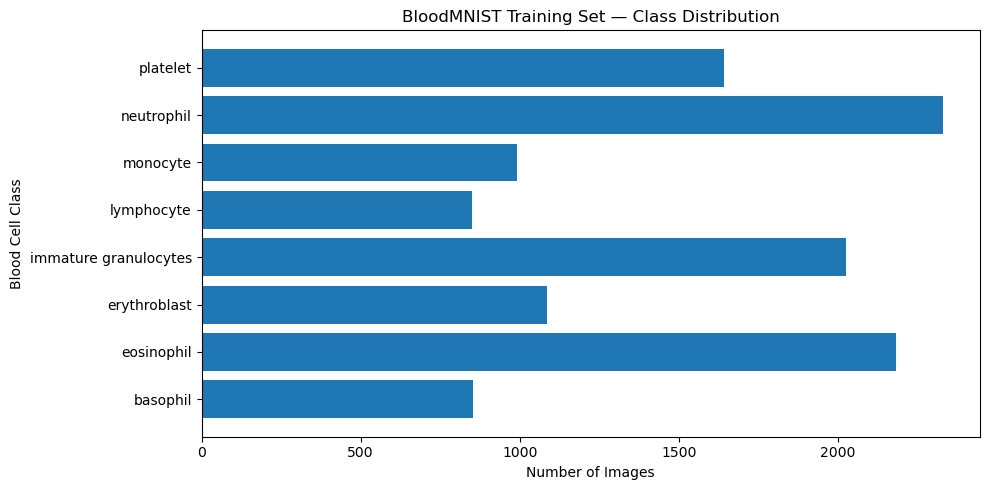

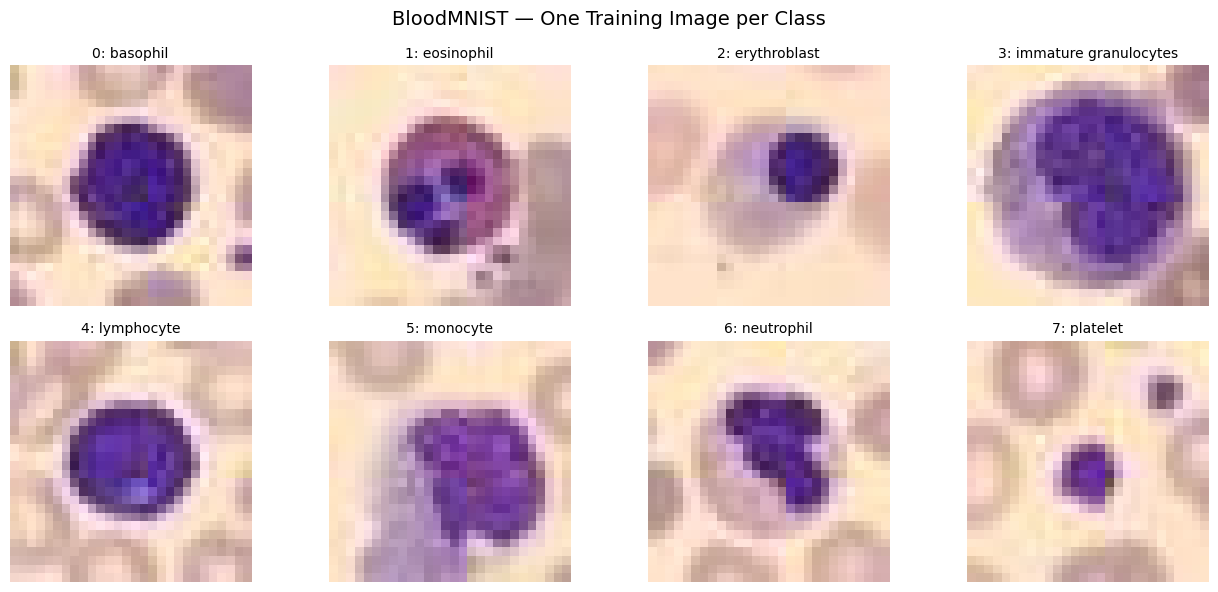


Training RGB statistics:
Mean (R, G, B): [0.794348 0.659659 0.696191]
Std  (R, G, B): [0.21563  0.241603 0.117889]


In [ ]:
# Count the number of images in each class across the official splits.
num_classes = len(info["label"])                  # Number of BloodMNIST classes: 8.
class_names = [info["label"][str(i)] for i in range(num_classes)]  # Names ordered by class ID.

class_counts = {}

for split_name, dataset in raw_datasets.items():
    labels = dataset.labels.reshape(-1)          # Convert labels from (N, 1) to (N,).
    counts = np.bincount(labels, minlength=num_classes)  # Count images for each class ID.
    class_counts[split_name] = counts            # Store the counts for this dataset split.


# Create one class-distribution table for training, validation, and testing.
class_distribution = pd.DataFrame(
    class_counts,                                # Three columns: Train, Validation, Test.
    index=class_names                            # Eight rows corresponding to the class names.
)

class_distribution.index.name = "Blood Cell Class"
class_distribution.loc["Total"] = class_distribution.sum(axis=0)  # Total images in each split.

print("\nBloodMNIST class distribution:")
display(class_distribution)


# Create a second class-count table indexed by numeric class IDs (0–7).
class_distribution_by_id = pd.DataFrame(
    {
        "Train": class_counts["Train"],             # Number of training images in each class.
        "Val": class_counts["Validation"],          # Number of validation images in each class.
        "Test": class_counts["Test"]                 # Number of test images in each class.
    },
    index=range(num_classes)                        # Use class IDs 0–7 as row indices.
)

class_distribution_by_id.index.name = "Class ID"   

# Display the class counts in numerical class order.
print("\nClass distribution by ID:")
display(class_distribution_by_id)


# Prepare class names and training counts for the distribution plot.
plot_names = [name.split("(")[0].strip() for name in class_names]  # Shorten long class names for readability.
train_counts = class_counts["Train"]               # Training sample counts for the eight classes.

# Plot the training class distribution to examine class imbalance.
plt.figure(figsize=(10, 5))                       
plt.barh(plot_names, train_counts)                 
plt.xlabel("Number of Images")                     
plt.ylabel("Blood Cell Class")                     
plt.title("BloodMNIST Training Set — Class Distribution")  
plt.tight_layout()                                
plt.show()                                        


# Select and visualize one training image from each of the eight classes.
train_labels = raw_train_dataset.labels.reshape(-1)  # Training labels as a 1D NumPy array.

fig, axes = plt.subplots(2, 4, figsize=(13, 6))  

for class_id, ax in enumerate(axes.flat):
    image_index = np.where(train_labels == class_id)[0][0]  # Find the first image of this class.
    image_tensor, _ = raw_train_dataset[image_index]  # Retrieve image after ToTensor().

    image = image_tensor.permute(1, 2, 0)        # Convert (C, H, W) to (H, W, C) for display.
    class_name = class_names[class_id].split("(")[0].strip()  # Shorten long labels in the title.

    ax.imshow(image)                            # Display the RGB image before standardization.
    ax.set_title(f"{class_id}: {class_name}", fontsize=10)
    ax.axis("off")                               # Hide axes for a cleaner image grid.

fig.suptitle("BloodMNIST — One Training Image per Class", fontsize=14)
plt.tight_layout()                              # Prevent overlapping titles and images.
plt.show()                                      # Display the completed image grid.


# Collect training images after ToTensor() to calculate RGB statistics.
train_images = torch.stack(
    [raw_train_dataset[i][0] for i in range(len(raw_train_dataset))]
)                                                # Shape: (N, 3, 28, 28), with pixels in [0, 1].

# Compute the mean and population standard deviation for each RGB channel.
train_mean = train_images.mean(dim=(0, 2, 3))      # Average over N, H, W; keep RGB channel dimension.
train_std = train_images.std(dim=(0, 2, 3), correction=0)  # Population std (ddof=0) for R, G, B.

assert torch.all(train_std > 0)                  # Avoid division by zero during normalization.

# Display the statistics calculated exclusively from the training dataset.
print("\nTraining RGB statistics:")
print("Mean (R, G, B):", train_mean.numpy().round(6))
print("Std  (R, G, B):", train_std.numpy().round(6))

del train_images                                 # Release the temporary training tensor from memory.


#### 1.2 — Class Distribution, Image Visualization & RGB Statistics: Results & Interpretation

**Implementation & Verification:**

- Successfully calculated class distributions across the three official dataset splits and visualized the training class counts.  

- Displayed eight representative training images, one from each blood cell class.  

- Computed per-channel RGB mean and standard deviation exclusively from training images after `ToTensor()`, before normalization.

**Results & Key Observations:**

- **Class Distribution:** The training set exhibits class imbalance. Neutrophils have the most training images (2,330; 19.5%), while lymphocytes have the fewest (849; 7.1%). The largest class contains approximately 2.74 times as many images as the smallest.  

- **Image Visualization:** The eight-image grid illustrates differences in cell appearance, shape, color, and internal structure. All images have a resolution of 28 × 28 pixels, limiting the visibility of fine cellular details.  

- **Training RGB Statistics:**  

  - Mean (R, G, B): `[0.794348, 0.659659, 0.696191]`  

  - Std (R, G, B): `[0.215630, 0.241603, 0.117889]`  
  
  - All statistics were calculated on the [0, 1] pixel scale using training data only.

**Interpretation:**

The observed class imbalance supports using macro-F1 as the primary evaluation metric, giving equal weight to all eight classes. The low image resolution may limit fine-grained visual information, while the training-derived RGB statistics provide a consistent normalization basis for M0, M1, and M2 without introducing validation or test data leakage.

The eight displayed images are illustrative and do not represent the full visual variability within each class.


### 1.3 — Preprocessing, DataLoaders & Batch Check

**Objective:** Apply training-derived RGB normalization to all official BloodMNIST splits, construct DataLoaders, and verify the resulting mini-batch tensors.

**Purpose:** Establish a consistent preprocessing and mini-batch pipeline for training and evaluating M0, M1, and M2.

**Procedure:**  

1. Convert the training RGB mean and standard deviation from Section 1.2 into Python lists.  

2. Define a shared preprocessing pipeline using `ToTensor()` followed by `Normalize()`, without data augmentation.  

3. Prepare the official training, validation, and test datasets using the same normalization statistics.  

4. Create three DataLoaders with batch size 128. Enable shuffling only for training, using a seed-controlled generator.  

5. Inspect a training mini-batch, convert labels into the format required by `CrossEntropyLoss`, and verify tensor shapes, data types, label ranges, and normalized pixel values.

**Expected Results:**
- The same training-derived RGB normalization is applied to all three official dataset splits.  

- Three functional DataLoaders with batch size 128.  

- Image batch shape `(B, 3, 28, 28)` with `float32` values.  

- Original batch labels reshaped from `(B, 1)` to `(B,)` and converted to `torch.int64`.  

- Verified class IDs from 0 to 7 and finite normalized pixel values.

**Role in the Experiment:** Provide consistent image preprocessing and mini-batch inputs for all three models under the shared experimental protocol.

**Important Distinction:** Validation and test images use normalization statistics calculated exclusively from the training set. Normalized pixel values may fall outside [0, 1], and individual mini-batches are not expected to have exactly zero mean or unit standard deviation.


In [ ]:
# Convert training-derived RGB statistics into Python lists for torchvision.
rgb_mean = train_mean.tolist()               # Three channel means: [mean_R, mean_G, mean_B].
rgb_std = train_std.tolist()                 # Three channel stds: [std_R, std_G, std_B].

# Define the same preprocessing transformation for all official dataset splits.
normalized_transform = transforms.Compose([
    transforms.ToTensor(),                   # Convert RGB images (H, W, C) to float tensors (C, H, W) in [0, 1].
    transforms.Normalize(                    # Standardize each RGB channel: (pixel - mean) / std.
        mean=rgb_mean,                       # Use channel means calculated only from the training set.
        std=rgb_std                          # Use channel standard deviations from the same training set.
    )
])


# Load the official datasets with the shared RGB normalization.
train_dataset = BloodMNIST(
    split="train",                           # Use the official training images and labels.
    root=str(DATA_DIR),                      # Read dataset files from the shared project data directory.
    transform=normalized_transform,          # Apply ToTensor() followed by training-derived normalization.
    download=False                           # Dataset files were already downloaded in Section 1.1.
)

val_dataset = BloodMNIST(
    split="val",                             
    root=str(DATA_DIR),
    transform=normalized_transform,          
    download=False
)

test_dataset = BloodMNIST(
    split="test",                            
    root=str(DATA_DIR),
    transform=normalized_transform,          # Use training statistics without recalculating them.
    download=False
)


# Create a fresh training DataLoader with reproducible sample shuffling.
def make_train_loader(seed: int) -> DataLoader:
    generator = torch.Generator().manual_seed(seed)  # Control random sample ordering independently of other operations.

    return DataLoader(
        train_dataset,                       # Read normalized training images and labels.
        batch_size=cfg.batch_size,           # Group up to 128 images into each mini-batch.
        shuffle=True,                        # Randomize training sample order for each epoch.
        generator=generator,                 # Use the specified seed to initialize the shuffle sequence.
        num_workers=0                        # Load data in the main process for simple cross-platform execution.
    )


# Initialize the training loader and create validation/test loaders.
train_loader = make_train_loader(cfg.seed)   # Initial training DataLoader using seed 42.

val_loader = DataLoader(
    val_dataset,                             # Read normalized validation samples.
    batch_size=cfg.batch_size,               # Use the same batch size as training.
    shuffle=False,                           # Preserve validation sample order.
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,                            # Read normalized test samples.
    batch_size=cfg.batch_size,
    shuffle=False,                           # Preserve test sample order for final evaluation.
    num_workers=0
)


# Display dataset sizes and the number of mini-batches in each loader.
print("Dataset sizes:")
print("  Train:", len(train_dataset))
print("  Validation:", len(val_dataset))
print("  Test:", len(test_dataset))

print("\nNumber of batches:")
print("  Train:", len(train_loader))
print("  Validation:", len(val_loader))
print("  Test:", len(test_loader))


# Retrieve one mini-batch and prepare the labels for multiclass classification.
images, labels = next(iter(train_loader))    # Get one batch of normalized images and original labels.
labels = labels.view(-1).long()              # Convert labels from (B, 1) to (B,) with torch.int64 dtype.

# Inspect tensor shapes, data types, class IDs, and normalized pixel values.
print("\nTraining mini-batch:")
print("  Images shape:", tuple(images.shape))   # Expected: (128, 3, 28, 28).
print("  Images dtype:", images.dtype)          # Expected: torch.float32.
print("  Labels shape:", tuple(labels.shape))   # Expected: (128,).
print("  Labels dtype:", labels.dtype)          # Expected: torch.int64.
print("  Class IDs:", torch.unique(labels).tolist())  # Display the classes appearing in this batch.
print("  Pixel range:", images.min().item(), images.max().item())  # Values may be outside [0, 1].

# Inspect the RGB mean and std of this mini-batch after normalization.
batch_mean = images.mean(dim=(0, 2, 3))       # Average across batch, height, and width; retain RGB channels.
batch_std = images.std(dim=(0, 2, 3), correction=0)  # Population std for each channel in this batch.

print("  Batch RGB mean:", batch_mean.tolist())  # May differ from [0, 0, 0] for a single batch.
print("  Batch RGB std:", batch_std.tolist())    # May differ from [1, 1, 1] for a single batch.


# Verify the essential tensor properties before model construction and training.
assert images.shape[1:] == (3, 28, 28)        # CNN input requires 3 RGB channels and 28×28 images.
assert labels.shape == (images.shape[0],)     # Each image must have exactly one class label.
assert torch.all((labels >= 0) & (labels < 8))  # Valid BloodMNIST class IDs are 0 through 7.
assert torch.isfinite(images).all()           # Confirm normalized pixels contain no NaN or infinite values.

print("\nData pipeline verification passed.")


Dataset sizes:
  Train: 11959
  Validation: 1712
  Test: 3421

Number of batches:
  Train: 94
  Validation: 14
  Test: 27

Training mini-batch:
  Images shape: (128, 3, 28, 28)
  Images dtype: torch.float32
  Labels shape: (128,)
  Labels dtype: torch.int64
  Class IDs: [0, 1, 2, 3, 4, 5, 6, 7]
  Pixel range: -3.9095826148986816 2.5770792961120605
  Batch RGB mean: [0.0037986862007528543, 0.0025886602234095335, 0.017435181885957718]
  Batch RGB std: [1.0002285242080688, 1.00433349609375, 0.9963544607162476]

Data pipeline verification passed.


#### 1.3 — Data Pipeline Verification: Results & Interpretation

**Implementation & Verification:**
 
- Successfully applied training-derived RGB normalization to all three official dataset splits and created functional DataLoaders.  

- All essential batch-shape, label-range, and numerical validity checks passed.

**Results & Key Observations:**

- **DataLoaders:** 94 training, 14 validation, and 27 test mini-batches with batch size 128.  

- **Images:** Shape `(128, 3, 28, 28)` and dtype `torch.float32`.  

- **Labels:** Shape `(128,)` and dtype `torch.int64`, compatible with `CrossEntropyLoss`.  

- **Normalized pixels:** Observed range approximately [-3.91, 2.58], with batch RGB means near 0 and standard deviations near 1.

**Interpretation:**

The data pipeline produces correctly shaped and normalized tensors for all three models. Pixel values outside [0, 1] are expected after standardization, and individual mini-batch statistics need not be exactly zero mean and unit variance. The verified pipeline is ready for model training.


## Part 2 — Define M0, M1, M2 & Initialize Weights

### Overview & Objectives

Implement three neural network architectures for eight-class BloodMNIST image classification: an MLP baseline (M0) and two CNN models with different classifier heads (M1 and M2).

This part focuses on understanding MLP and CNN architectures, spatial feature extraction, Flatten versus Global Average Pooling (GAP), weight initialization, tensor shapes, and trainable parameter counts.

All three models receive normalized RGB images with shape `(B, 3, 28, 28)` and produce eight raw classification logits with shape `(B, 8)`.

### Workflow & Section Guide

- **2.1 — M0: Two-Hidden-Layer MLP:** Implement an `MLP(nn.Module)` class using Flatten, two fully connected hidden layers (256 and 128 neurons), ReLU activations, Dropout(0.2), and an output Linear layer for eight-class classification. No Batch Normalization.

- **2.2 — M1/M2: Two-Block CNNs:** Implement a `SimpleCNN(nn.Module)` class with two Conv2d → BatchNorm2d → ReLU → MaxPool2d blocks (32 and 64 channels). Use `head="flatten"` for M1 and `head="gap"` for M2, with Dropout(0.2) before the final Linear classifier.

- **2.3 — He Uniform Initialization & Forward Checks:** Apply He/Kaiming Uniform initialization to the MLP hidden Linear weights and CNN convolutional weights, while retaining PyTorch default initialization for the output Linear layers. Verify output tensor shapes and count trainable parameters for all three models.

### Important Objects & Their Roles

- `MLP`: Defines the M0 architecture using fully connected layers to classify flattened RGB images.  

- `SimpleCNN`: Defines the shared two-block CNN architecture with selectable Flatten or GAP classifier heads.  

- `nn.Flatten`: Converts image tensors or feature maps into feature vectors while preserving the batch dimension.  

- `nn.Conv2d`: Extracts spatial features from image inputs through learnable convolutional filters.  

- `nn.BatchNorm2d`: Normalizes intermediate CNN activations using learnable scale and shift parameters.  

- `nn.ReLU`: Introduces nonlinearity after hidden Linear or convolutional transformations.  

- `nn.MaxPool2d`: Reduces spatial dimensions within each CNN block.  

- `nn.AdaptiveAvgPool2d(1)`: Performs Global Average Pooling, reducing each feature map to one value.  

- `nn.Dropout`: Applies dropout with probability 0.2 during training to provide regularization.  

- `nn.Linear`: Performs fully connected transformations for hidden representations and final classification logits.  

- `init_weights()`: Applies He/Kaiming Uniform initialization to the specified hidden Linear and convolutional weights.  

- `count_parameters()`: Counts trainable model parameters for architecture verification and comparison.

### Expected Outcomes & Role in the Experiment

Three correctly implemented and initialized models:

| Model | Architecture | Trainable Parameters |
|---|---|---:|
| **M0** | MLP: Flatten → Linear(2352, 256) → ReLU → Dropout → Linear(256, 128) → ReLU → Dropout → Linear(128, 8) | 636,296 |
| **M1** | Two-block CNN + BatchNorm + Flatten(3136) → Dropout → Linear(3136, 8) | 44,680 |
| **M2** | Two-block CNN + BatchNorm + GAP → Flatten(64) → Dropout → Linear(64, 8) | 20,104 |

Expected verification results:

- All three models successfully process input tensors with shape `(B, 3, 28, 28)` and return raw logits with shape `(B, 8)`.  

- Hidden Linear weights in M0 and Conv2d weights in M1/M2 use He/Kaiming Uniform initialization.  

- Final output Linear layers retain PyTorch default initialization.  

- Trainable parameter counts match the predefined architectures.  

- M1 and M2 use the same CNN feature-extractor design but different classifier heads. They do not share trained weights.

These verified architectures provide the basis for comparing MLP versus CNN performance and Flatten versus GAP parameter efficiency under the shared training protocol.

---

### 2.1 — M0: Two-Hidden-Layer MLP

**Objective:** Implement a multilayer perceptron (MLP) with two fully connected hidden layers as the non-convolutional baseline for BloodMNIST classification.

**Purpose:** Establish a baseline architecture that processes flattened RGB images without convolutional layers, spatial pooling, or Batch Normalization.

**Procedure:**
1. Define an `MLP(nn.Module)` class with an `__init__()` method for constructing the network layers.
2. Flatten each RGB image from `(3, 28, 28)` into a vector of 2,352 features.
3. Define two hidden Linear layers with 256 and 128 neurons, each followed by ReLU and Dropout(0.2).
4. Add a final Linear layer that maps 128 hidden features to eight classification logits.
5. Implement `forward()` to specify the sequential flow of input tensors through the network.

**Expected Results:**
- An `MLP` class implementing the architecture: Flatten → Linear(2352, 256) → ReLU → Dropout(0.2) → Linear(256, 128) → ReLU → Dropout(0.2) → Linear(128, 8).
- Input shape `(B, 3, 28, 28)` and expected output shape `(B, 8)`.
- An architecture designed to contain 636,296 trainable parameters, to be verified in Section 2.3.

**Important Distinction:** The final Linear layer produces raw logits without ReLU or Softmax. Custom He/Kaiming Uniform initialization and forward-pass verification will be performed in Section 2.3.


In [ ]:
# Define the MLP baseline with two fully connected hidden layers.
class MLP(nn.Module):
    def __init__(self, dropout_p: float = 0.2):
        super().__init__()                     

        # Define the input transformation and three fully connected layers.
        self.flatten = nn.Flatten()            # Flatten RGB images: (B, 3, 28, 28) -> (B, 2352).
        self.fc1 = nn.Linear(2352, 256)        # Hidden layer 1: 2352 input features -> 256 neurons.
        self.fc2 = nn.Linear(256, 128)         # Hidden layer 2: 256 -> 128 neurons.
        self.output = nn.Linear(128, 8)        # Output layer: 128 features -> 8 raw classification logits.

        # Define activation and regularization modules shared by both hidden layers.
        self.relu = nn.ReLU()                  # ReLU(x) = max(0, x); introduces nonlinearity.
        self.dropout = nn.Dropout(p=dropout_p) # Randomly zero activations with probability p during training.

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Flatten each input image into a feature vector.
        x = self.flatten(x)                   # (B, 3, 28, 28) -> (B, 2352).

        # Hidden layer 1: Linear transformation, ReLU activation, and Dropout.
        x = self.fc1(x)                       # (B, 2352) -> (B, 256).
        x = self.relu(x)                      # Set negative activations to zero; shape unchanged.
        x = self.dropout(x)                   # Apply Dropout(0.2) during training; shape unchanged.

        # Hidden layer 2: Repeat the same sequence with 128 neurons.
        x = self.fc2(x)                       # (B, 256) -> (B, 128).
        x = self.relu(x)                      # Apply ReLU to the second hidden layer.
        x = self.dropout(x)                   # Apply a new Dropout mask during training.

        # Produce eight raw logits for multiclass classification.
        logits = self.output(x)               # (B, 128) -> (B, 8); no final ReLU or Softmax.

        return logits                         


### 2.2 — M1/M2: Two-Block CNNs

**Objective:** Implement two convolutional neural network (CNN) architectures with a shared feature-extractor design and different classifier heads for BloodMNIST classification.

**Purpose:** Examine how convolutional layers preserve spatial image information and establish the architectures needed to compare Flatten and Global Average Pooling (GAP).

**Procedure:** 

1. Define a `SimpleCNN(nn.Module)` class with a configurable classifier head (`"flatten"` or `"gap"`).  

2. Construct two convolutional blocks, each following Conv2d → BatchNorm2d → ReLU → MaxPool2d, with 32 and 64 output channels.  

3. Implement the classifier heads:
   - **M1 (Flatten):** Flatten the `(B, 64, 7, 7)` feature maps into `(B, 3136)`.  

   - **M2 (GAP):** Apply `AdaptiveAvgPool2d(1)` to obtain `(B, 64, 1, 1)`, then Flatten into `(B, 64)`.  

4. Apply Dropout(0.2) before the final Linear classifier.  

5. Implement `forward()` to produce eight raw classification logits per image.

**Expected Results:**  

- A reusable `SimpleCNN` class supporting both M1 and M2.  

- Two convolutional blocks producing feature maps with shape `(B, 64, 7, 7)`.  

- M1: Flatten classifier with 44,680 trainable parameters.  

- M2: GAP classifier with 20,104 trainable parameters.  

- Both models produce raw logits with shape `(B, 8)`.  

- Output shapes and parameter counts will be verified in Section 2.3.

**Important Distinction:** Both CNNs use the same feature-extractor architecture but are initialized and trained independently. Conv2d layers retain their default biases, BatchNorm uses PyTorch default initialization, and final Linear layers are not custom-initialized. He/Kaiming Uniform initialization for Conv2d weights will be applied in Section 2.3.


In [ ]:
# Define a two-block CNN with either a Flatten or GAP classifier head.
class SimpleCNN(nn.Module):
    def __init__(self, head: str = "flatten", dropout_p: float = 0.2):
        super().__init__()                     

        # Validate the classifier head before constructing the network.
        if head not in ("flatten", "gap"):       # Only two classifier-head designs are used in this experiment.
            raise ValueError("head must be 'flatten' or 'gap'.")

        # Block 1: extract 32 feature maps and reduce image resolution from 28×28 to 14×14.
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=True),  # (B, 3, 28, 28) -> (B, 32, 28, 28).
            nn.BatchNorm2d(32),                # Normalize the 32 output channels and learn scale/shift.
            nn.ReLU(),                         # Replace negative activations with zero.
            nn.MaxPool2d(2)                    # Downsample each feature map: 28×28 -> 14×14.
        )

        # Block 2: extract 64 feature maps and reduce resolution from 14×14 to 7×7.
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=True), # (B, 32, 14, 14) -> (B, 64, 14, 14).
            nn.BatchNorm2d(64),                # Normalize the 64 output channels.
            nn.ReLU(),                         # Introduce nonlinearity after BatchNorm.
            nn.MaxPool2d(2)                    # Downsample each feature map: 14×14 -> 7×7.
        )

        # Select the classifier head while keeping the CNN feature extractor unchanged.
        self.pool = (
            nn.Identity()                      # M1: preserve all 64 feature maps of size 7×7.
            if head == "flatten"
            else nn.AdaptiveAvgPool2d(1)       # M2: average each feature map into one value (64, 1, 1).
        )

        self.flatten = nn.Flatten()            # M1: (B, 64, 7, 7) -> (B, 3136); M2: (B, 64, 1, 1) -> (B, 64).
        self.dropout = nn.Dropout(p=dropout_p) # Drop 20% of classifier-input features during training.

        # Define the final Linear layer according to the selected head.
        classifier_features = 3136 if head == "flatten" else 64  # M1 uses 64×7×7; M2 uses 64 features.
        self.classifier = nn.Linear(classifier_features, 8)       # Map features to 8 raw BloodMNIST logits.

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Extract spatial features using the two convolutional blocks.
        x = self.block1(x)                     # (B, 3, 28, 28) -> (B, 32, 14, 14).
        x = self.block2(x)                     # (B, 32, 14, 14) -> (B, 64, 7, 7).

        # Apply the selected pooling strategy and flatten the features.
        x = self.pool(x)                       # M1: unchanged; M2: (B, 64, 7, 7) -> (B, 64, 1, 1).
        x = self.flatten(x)                    # M1: (B, 3136); M2: (B, 64).

        # Regularize classifier inputs and produce the final classification scores.
        x = self.dropout(x)                   # Randomly zero features during training; preserve shape.
        logits = self.classifier(x)           # M1/M2: feature vector -> (B, 8).

        return logits                         


### 2.3 — He Uniform Initialization & Forward Checks

**Objective:** Apply the predefined He/Kaiming Uniform weight initialization and verify the architectures, output shapes, and trainable parameter counts of M0, M1, and M2.

**Purpose:** Confirm that all three models are correctly constructed and initialized before starting the training experiments.

**Procedure:**
1. Define an `init_weights()` function to apply He/Kaiming Uniform initialization to the two hidden Linear layers of M0 and the Conv2d layers of M1/M2.  

2. Define a `count_parameters()` function to count trainable model parameters.  

3. Reset the random seed and create fresh instances of M0, M1, and M2 using their predefined architectures.  

4. Apply weight initialization and display each model architecture.  

5. Perform a forward pass using a dummy batch with shape `(2, 3, 28, 28)`.  

6. Verify the output logits shape, trainable parameter counts, and relevant CNN feature dimensions.

**Expected Results:**

| Model | Output Shape | Trainable Parameters |
|---|---|---:|
| M0 — MLP | `(2, 8)` | 636,296 |
| M1 — CNN + BN + Flatten | `(2, 8)` | 44,680 |
| M2 — CNN + BN + GAP | `(2, 8)` | 20,104 |

- Both CNNs produce backbone feature maps with shape `(2, 64, 7, 7)`.  

- M1 uses 3,136 classifier input features; M2 uses 64.  

- All output logits contain finite numerical values.

**Important Distinction:** He/Kaiming Uniform initialization is applied only to the designated hidden Linear and convolutional weights. Biases, BatchNorm parameters, and final output Linear layers retain PyTorch default initialization. These models are used only for structural verification; fresh models will be created for official training in Part 4.


In [31]:
# Apply He/Kaiming Uniform initialization to the specified hidden weights.
def init_weights(model: nn.Module) -> None:
    if isinstance(model, MLP):
        layers = [model.fc1, model.fc2]           # Initialize only M0's two hidden Linear layers.
    elif isinstance(model, SimpleCNN):
        layers = [model.block1[0], model.block2[0]]  # Initialize the Conv2d layers in both CNN blocks.
    else:
        raise TypeError("Expected an MLP or SimpleCNN model.")

    # Initialize weights for ReLU while keeping biases and output layers unchanged.
    for layer in layers:
        nn.init.kaiming_uniform_(
            layer.weight,                         # Modify the selected weight tensor in place.
            mode="fan_in",                         # Scale weights based on the number of input connections.
            nonlinearity="relu"                    # Use the initialization gain appropriate for ReLU.
        )


# Count the total number of trainable parameters in a model.
def count_parameters(model: nn.Module) -> int:
    return sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )                                               # Count all trainable weight and bias elements.


# Define the expected parameter counts for the three fixed model architectures.
expected_params = {
    "M0": 636_296,                                  # Two-hidden-layer MLP baseline.
    "M1": 44_680,                                   # CNN with a Flatten classifier head.
    "M2": 20_104                                    # CNN with a GAP classifier head.
}

dummy_images = torch.zeros(2, 3, 28, 28)            # Two synthetic RGB images for checking model shapes.


# Construct, initialize, and verify each model independently.
for model_name in ["M0", "M1", "M2"]:
    set_seed(cfg.seed)                              # Reset seed before constructing each model.

    # Create the architecture selected by the model name.
    if model_name == "M0":
        model = MLP(dropout_p=cfg.dropout)           # M0: two-hidden-layer MLP.
    elif model_name == "M1":
        model = SimpleCNN(head="flatten", dropout_p=cfg.dropout)  # M1: CNN with Flatten.
    else:
        model = SimpleCNN(head="gap", dropout_p=cfg.dropout)      # M2: CNN with GAP.

    init_weights(model)                             # Apply He Uniform to designated hidden weights only.

    # Inspect the model architecture without training or updating parameters.
    print(f"\n{model_name} — Model Architecture:")
    print(model)                                    # Display registered layers and their configurations.

    model.eval()                                    # Disable Dropout; use BatchNorm running statistics.
    with torch.no_grad():                           # Perform inference without tracking gradients.
        logits = model(dummy_images)                # Forward pass: (2, 3, 28, 28) -> (2, 8).

    # Check output dimensions, numerical validity, and trainable parameters.
    num_params = count_parameters(model)            # Count trainable weights and biases.
    assert logits.shape == (2, 8)                   # Each image must produce eight classification logits.
    assert torch.isfinite(logits).all()             # Confirm that logits contain no NaN or infinity.
    assert num_params == expected_params[model_name]  # Confirm the parameter count matches the design.

    print("Input shape:", tuple(dummy_images.shape))
    print("Output shape:", tuple(logits.shape))
    print("Trainable parameters:", f"{num_params:,}")

    # Verify the classifier dimensions of the two CNN architectures.
    if model_name != "M0":
        expected_features = 3136 if model_name == "M1" else 64  # Flatten versus GAP input size.
        assert model.classifier.in_features == expected_features

        print("Classifier input features:", model.classifier.in_features)

    # Display the parameter counts of M0's three Linear layers.
    if model_name == "M0":
        print("fc1 parameters:", f"{count_parameters(model.fc1):,}")
        print("fc2 parameters:", f"{count_parameters(model.fc2):,}")
        print("Output parameters:", f"{count_parameters(model.output):,}")

    print(f"{model_name} verification passed.")


print("\nAll three models passed architecture verification.")



M0 — Model Architecture:
MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=2352, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (output): Linear(in_features=128, out_features=8, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
)
Input shape: (2, 3, 28, 28)
Output shape: (2, 8)
Trainable parameters: 636,296
fc1 parameters: 602,368
fc2 parameters: 32,896
Output parameters: 1,032
M0 verification passed.

M1 — Model Architecture:
SimpleCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=Tru

#### 2.3 — Architecture Verification: Results & Interpretation

**Implementation & Verification:**

- Successfully constructed and initialized M0, M1, and M2 using the predefined architectures and weight initialization policy.  

- All three models passed forward-pass, output-shape, parameter-count, and numerical validity checks.

**Results & Key Observations:**

| Model | Output Shape | Trainable Parameters | Classifier Input Features |
|---|---|---:|---:|
| M0 — MLP | `(2, 8)` | 636,296 | 128 |
| M1 — CNN + BN + Flatten | `(2, 8)` | 44,680 | 3,136 |
| M2 — CNN + BN + GAP | `(2, 8)` | 20,104 | 64 |

- All models successfully converted dummy RGB inputs `(2, 3, 28, 28)` into eight raw logits per image.  

- M1 and M2 use the same two-block CNN feature-extractor architecture but different classifier heads.  

- GAP reduces M2's total trainable parameters by 24,576 (approximately 55.0%) compared with M1.

**Interpretation:**

The three models satisfy the predefined structural requirements and are ready for training. M2 uses substantially fewer parameters than M1, demonstrating the architectural parameter reduction achieved by replacing Flatten with GAP. Whether this reduction affects classification performance will be evaluated experimentally.


## Part 3 — Basic Training & Validation

### Overview & Objectives

Implement reusable PyTorch functions for training, validating, and selecting the best checkpoints of the three BloodMNIST models (M0, M1, and M2).

This part focuses on the fundamental neural network training process: forward propagation, cross-entropy loss calculation, backpropagation, gradient-based parameter updates, and model evaluation.

The training utilities will follow the shared experimental protocol: Adam optimization with a learning rate of 0.001, 12 fixed epochs per model, and best-checkpoint selection based on validation macro-F1, without early stopping.

### Workflow & Section Guide

- **3.1 — `train_one_epoch()`:** Implement a reusable training function using `model.train()`, mini-batch forward propagation, CrossEntropyLoss, `loss.backward()`, and `optimizer.step()`. Calculate the sample-weighted average training loss across one complete epoch.

- **3.2 — `evaluate()`:** Implement a reusable evaluation function using `model.eval()` and `torch.no_grad()`. Collect true labels and predictions across all mini-batches, then calculate evaluation loss, accuracy, and macro-F1 over the complete dataset.

- **3.3 — `train_model()`:** Combine the training and evaluation functions into a multi-epoch training loop. Record epoch-level metrics, complete all 12 epochs, and save the model checkpoint whenever validation macro-F1 improves. Return the training history and best epoch.

### Important Objects & Their Roles

- `nn.CrossEntropyLoss`: Computes multiclass classification loss directly from raw logits and integer class labels.  

- `optimizer`: Updates trainable model parameters using their calculated gradients; Adam will be used in the official training runs.  

- `train_one_epoch()`: Performs one complete training epoch and returns the average training loss.  

- `evaluate()`: Calculates dataset-level loss, accuracy, and macro-F1 without updating model parameters.  

- `train_model()`: Coordinates multi-epoch training, validation, history recording, and best-checkpoint selection.  

- `history_df`: Stores epoch-level training loss, validation loss, validation accuracy, and validation macro-F1 in a pandas DataFrame.  

- `model.state_dict()`: Provides model parameters and persistent buffers for checkpoint saving.  

- `best_epoch`: Identifies the earliest epoch achieving the highest validation macro-F1.

### Expected Outcomes & Role in the Experiment

Three reusable training and evaluation functions:

| Function | Primary Responsibility | Expected Output |
|---|---|---|
| `train_one_epoch()` | Train one epoch and update model parameters | Average training loss |
| `evaluate()` | Evaluate classification performance without parameter updates | Loss, accuracy, macro-F1, `y_true`, `y_pred` |
| `train_model()` | Run 12 epochs, record metrics, and select the best checkpoint | History DataFrame, best epoch, saved `.pt` checkpoint |

Expected implementation results:

- A shared training procedure using forward propagation, CrossEntropyLoss, backpropagation, and optimizer updates.  

- Sample-weighted average loss calculated across all images in each epoch.  

- Validation accuracy and macro-F1 computed from predictions across the entire validation set, rather than averaged mini-batch metrics.  

- A training history containing epoch, training loss, validation loss, validation accuracy, and validation macro-F1.  

- Best-checkpoint selection based exclusively on validation macro-F1, retaining the earlier checkpoint in the event of a tie.  

- A complete 12-epoch training protocol without early stopping.

The resulting functions provide a consistent training and validation foundation for all three models. The official training runs will be executed in Part 4, while the held-out test set remains excluded from training and checkpoint selection.

---


### 3.1 — Training One Epoch: `train_one_epoch()`

**Objective:** Implement a reusable PyTorch function to train a neural network for one complete epoch using mini-batch gradient descent and the Adam optimizer.

**Purpose:** Understand the fundamental training process: forward propagation, loss calculation, backpropagation, and parameter updates.

**Procedure:**  

1. Define `nn.CrossEntropyLoss()` for eight-class classification using raw logits.  

2. Implement `train_one_epoch()` to accept a model, training DataLoader, loss function, optimizer, and computation device.  

3. Set the model to training mode using `model.train()`.  

4. For each mini-batch:  

   - Move images and labels to the selected device and prepare labels as 1D integer class indices.  

   - Clear existing gradients using `optimizer.zero_grad()`.  

   - Perform a forward pass to generate classification logits.  

   - Calculate cross-entropy loss between logits and true labels.  

   - Compute gradients using `loss.backward()`.  

   - Update model parameters using `optimizer.step()`.  

5. Calculate the average training loss across all samples in the epoch.

**Expected Results:**  

- A reusable `train_one_epoch()` function compatible with M0, M1, and M2.  

- Model parameters updated through gradient-based optimization.  

- One floating-point value representing the sample-weighted average training loss for the completed epoch.

**Important Distinction:** `CrossEntropyLoss()` accepts raw logits without an additional Softmax layer. Training loss is averaged over all samples, not calculated as an unweighted average of mini-batch losses.


In [32]:
# Define the loss function for eight-class BloodMNIST classification.
criterion = nn.CrossEntropyLoss()                  # Calculate multiclass cross-entropy from raw logits and class labels.


# Train a neural network for one complete epoch.
def train_one_epoch(
    model: nn.Module,
    train_loader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    device: torch.device
) -> float:

    model.train()                                 # Enable training behavior, including Dropout and BatchNorm updates.
    total_loss = 0.0                              # Accumulate batch losses weighted by the number of images.
    total_samples = 0                             # Count all training images processed during this epoch.

    # Process each mini-batch from the training DataLoader.
    for images, labels in train_loader:
        images = images.to(device)                 # Move input images to the same device as the model.
        labels = labels.view(-1).long().to(device) # Convert (B, 1) labels to (B,) with torch.int64 dtype.

        # Perform forward propagation, backpropagation, and parameter updates.
        optimizer.zero_grad()                      # Clear gradients left from the previous mini-batch.
        logits = model(images)                     # Forward pass: (B, 3, 28, 28) -> (B, 8) raw logits.
        loss = criterion(logits, labels)           # Calculate the mean cross-entropy loss for this mini-batch.
        loss.backward()                            # Compute gradients of the loss with respect to model parameters.
        optimizer.step()                           # Update trainable parameters using the Adam optimizer.

        # Accumulate the batch loss to compute the sample-weighted epoch average.
        batch_size = images.size(0)                # Number of images in this batch; the last batch may be smaller.
        total_loss += loss.item() * batch_size     # Convert mean batch loss into the sum of sample losses.
        total_samples += batch_size                # Add the number of processed images to the epoch total.

    # Return the average training loss across all images in this epoch.
    avg_train_loss = total_loss / total_samples    # Total sample loss divided by the number of training images.

    return avg_train_loss                          # Return one Python float for training history and learning curves.


### 3.2 — Model Evaluation: `evaluate()`

**Objective:** Implement a reusable PyTorch function to evaluate classification performance without updating model parameters.

**Purpose:** Measure validation and test performance consistently using cross-entropy loss, accuracy, and macro-averaged F1-score.

**Procedure:**
1. Define an `evaluate()` function that accepts a model, DataLoader, loss function, and computation device.  

2. Set the model to evaluation mode using `model.eval()` and disable gradient tracking with `torch.no_grad()`.  

3. For each mini-batch:  

   - Move images and labels to the selected device and reshape labels into 1D integer class indices.  

   - Perform a forward pass to obtain eight raw classification logits per image.  

   - Calculate cross-entropy loss without updating model parameters.  

   - Obtain predicted class IDs using `argmax(dim=1)`.  

   - Collect true and predicted labels across all mini-batches.  

4. Compute sample-weighted average loss, accuracy, and macro-F1 across the complete dataset.  

5. Return the evaluation metrics and collected labels/predictions.

**Expected Results:** 

- A reusable `evaluate()` function compatible with M0, M1, and M2.  

- Average evaluation loss, classification accuracy, and macro-F1.  

- Complete `y_true` and `y_pred` lists for subsequent error analysis.  

- No gradient computation or model parameter updates.

**Important Distinction:** Accuracy and macro-F1 are computed using predictions from the entire evaluation dataset, not by averaging metrics calculated separately for individual mini-batches. Macro-F1 assigns equal weight to each of the eight blood cell classes.


In [33]:
# Evaluate a model without computing gradients or updating its parameters.
def evaluate(
    model: nn.Module,
    data_loader: DataLoader,
    criterion: nn.Module,
    device: torch.device
) -> dict:

    model.eval()                                  # Disable Dropout and use BatchNorm running statistics.
    total_loss = 0.0                              # Accumulate batch losses weighted by sample counts.
    total_samples = 0                             # Count all evaluated images.
    y_true = []                                   # Store true class IDs from every mini-batch.
    y_pred = []                                   # Store predicted class IDs from every mini-batch.

    # Process all mini-batches without building a gradient computation graph.
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)            # Move image tensors to the model's computation device.
            labels = labels.view(-1).long().to(device)  # Convert labels from (B, 1) to (B,) with int64 dtype.

            # Perform forward propagation and calculate the classification loss.
            logits = model(images)                # Generate eight raw logits per image: (B, 8).
            loss = criterion(logits, labels)       # Calculate mean cross-entropy loss for this mini-batch.
            predictions = logits.argmax(dim=1)    # Select the class with the highest logit for each image.

            # Accumulate loss according to the number of images in each mini-batch.
            batch_size = images.size(0)           # Number of images in the current mini-batch.
            total_loss += loss.item() * batch_size  # Convert mean batch loss into summed sample loss.
            total_samples += batch_size           # Update the total number of evaluated images.

            # Collect true labels and predictions for dataset-level evaluation.
            y_true.extend(labels.cpu().tolist())       # Move true labels to CPU and append their class IDs.
            y_pred.extend(predictions.cpu().tolist())  # Move predictions to CPU and append their class IDs.

    # Compute evaluation metrics across the complete dataset.
    avg_loss = total_loss / total_samples         # Sample-weighted average cross-entropy loss.
    accuracy = accuracy_score(y_true, y_pred)     # Fraction of images classified correctly.
    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=range(8),                          # Include all eight BloodMNIST classes in macro-F1.
        average="macro",                          # Compute the unweighted mean of eight class F1-scores.
        zero_division=0                           # Assign F1=0 when a class has undefined precision/recall.
    )

    # Return metrics and predictions for validation, testing, and error analysis.
    return {
        "loss": avg_loss,                         # Average cross-entropy loss across all evaluated images.
        "accuracy": accuracy,                     # Overall classification accuracy, between 0 and 1.
        "macro_f1": macro_f1,                     # Macro-averaged F1-score, between 0 and 1.
        "y_true": y_true,                         # True class IDs, one per evaluated image.
        "y_pred": y_pred                          # Predicted class IDs, one per evaluated image.
    }


### 3.3 — Multi-Epoch Training & Best Checkpoint: `train_model()`

**Objective:** Implement a reusable training function that runs a fixed number of epochs, records training and validation metrics, and saves the best-performing model checkpoint.

**Purpose:** Coordinate the training and evaluation functions while selecting model weights based on validation macro-F1.

**Procedure:**  

1. Define `train_model()` to accept a model, training and validation DataLoaders, loss function, optimizer, computation device, number of epochs, and checkpoint path.  

2. For each epoch:  

   - Call `train_one_epoch()` to update model parameters and obtain average training loss.  

   - Call `evaluate()` to calculate validation loss, accuracy, and macro-F1.  
     
   - Record the epoch-level metrics in a training history.  

   - Save the model's `state_dict()` when validation macro-F1 improves.  

   - Display the epoch number and training/validation metrics.  

3. Convert the recorded metrics into a pandas DataFrame.  

4. Return the training history and best validation-selected epoch.

**Expected Results:**
- A reusable `train_model()` function compatible with M0, M1, and M2.  

- A training history DataFrame containing epoch, training loss, validation loss, validation accuracy, and validation macro-F1.  

- One best validation macro-F1 checkpoint saved as a `.pt` file.  

- The epoch number corresponding to the best checkpoint.

**Important Distinction:** All 12 epochs are completed without early stopping. The best checkpoint is selected using validation macro-F1, not training loss, validation accuracy, or test performance. If validation macro-F1 is tied, the earlier checkpoint is retained.


In [34]:
# Train a model for multiple epochs and save its best validation-selected checkpoint.
def train_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    device: torch.device,
    epochs: int,
    checkpoint_path: Path
) -> tuple[pd.DataFrame, int]:

    # Prepare the training history and best-checkpoint tracking variables.
    history = []                                  # Store training and validation metrics for each epoch.
    best_val_macro_f1 = -1.0                      # Start below the valid F1 range [0, 1] to save the first checkpoint.
    best_epoch = 0                                # Record the epoch with the highest validation macro-F1.

    # Train and validate the model for the predefined number of epochs.
    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(              # Train one full epoch and update model weights.
            model, train_loader, criterion, optimizer, device
        )

        val_results = evaluate(                   # Evaluate the updated model without changing its parameters.
            model, val_loader, criterion, device
        )

        # Record the metrics from the current epoch.
        history.append({
            "epoch": epoch,                       # Epoch number, starting from 1.
            "train_loss": train_loss,             # Sample-weighted average training loss.
            "val_loss": val_results["loss"],      # Average cross-entropy loss on the validation set.
            "val_accuracy": val_results["accuracy"],  # Fraction of correctly classified validation images.
            "val_macro_f1": val_results["macro_f1"]   # Mean F1 across the eight blood cell classes.
        })

        # Save the model only when validation macro-F1 improves.
        if val_results["macro_f1"] > best_val_macro_f1:
            best_val_macro_f1 = val_results["macro_f1"]  # Update the highest validation macro-F1.
            best_epoch = epoch                          # Record when the best validation score occurred.
            torch.save(model.state_dict(), checkpoint_path)  # Save the current model weights and buffers.

        # Display training and validation progress after each epoch.
        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_results['loss']:.4f} | "
            f"Val Acc: {val_results['accuracy']:.4f} | "
            f"Val Macro-F1: {val_results['macro_f1']:.4f}"
        )

    # Convert epoch-level records into a DataFrame for analysis and CSV export.
    history_df = pd.DataFrame(history)            # Each row represents one completed training epoch.

    # Report the best validation-selected checkpoint after all epochs.
    print(f"\nBest epoch: {best_epoch}")
    print(f"Best validation macro-F1: {best_val_macro_f1:.4f}")
    print(f"Checkpoint saved to: {checkpoint_path}")

    return history_df, best_epoch                 # Return the training history and best checkpoint epoch.


## Part 4 — Official Training: Only Three Runs

### Overview & Objectives

Train the three BloodMNIST models (M0, M1, and M2) in separate runs under a shared experimental protocol to compare their validation performance.

Each model is trained for 12 fixed epochs using the Adam optimizer (learning rate = 0.001), batch size 128, and random seed 42. All models use the same official dataset splits and training-derived RGB normalization statistics.

This part applies the training and evaluation functions developed in Part 3 to conduct the official experiments, select the best validation checkpoints, record training histories, and visualize learning curves.

### Workflow & Section Guide

- **4.1 — Train M0/M1/M2:** Train each model in a separate run. Reset the random seed, construct a fresh model, apply He/Kaiming Uniform initialization to the designated weights, create a new Adam optimizer and seeded training DataLoader, and call `train_model()`. Save the checkpoint with the highest validation macro-F1 for each model.

- **4.2 — Curves & Validation Table:** Save the three epoch-level training histories as CSV files, generate learning curves showing training/validation loss and validation macro-F1, and summarize model parameter counts, best epochs, and best validation macro-F1 scores in a comparison table.

### Important Objects & Their Roles

- `cfg`: Provides the fixed experimental settings and shared results directory.  

- `MLP`, `SimpleCNN`: Define the M0, M1, and M2 architectures.  

- `set_seed()`: Resets random-number generators before each official training run.  

- `init_weights()`: Applies the predefined He/Kaiming Uniform initialization to hidden Linear and Conv2d weights.  

- `make_train_loader()`: Creates a fresh training DataLoader with seed-controlled shuffling.  

- `train_model()`: Coordinates 12 training/validation epochs, records metrics, and saves the best validation-selected checkpoint.  

- `count_parameters()`: Counts trainable model parameters for architectural comparison.  

- `history_df`: Stores epoch-level training loss, validation loss, validation accuracy, and validation macro-F1.  

- `validation_summary`: Summarizes parameter counts, best epochs, and best validation macro-F1 scores across the three models.

### Expected Outcomes & Role in the Experiment

Three official training runs, one for each model:

| Model | Seed | Epochs | Optimizer | Checkpoint Selection |
|---|---:|---:|---|---|
| **M0 — MLP Baseline** | 42 | 12 | Adam (LR = 0.001) | Best validation macro-F1 |
| **M1 — CNN + BN + Flatten** | 42 | 12 | Adam (LR = 0.001) | Best validation macro-F1 |
| **M2 — CNN + BN + GAP** | 42 | 12 | Adam (LR = 0.001) | Best validation macro-F1 |

Expected outputs:

- **3 trained models:** Each trained from a fresh initialization with its own Adam optimizer and seeded training DataLoader.  

- **3 model checkpoints:** One best validation macro-F1 checkpoint per model, saved as a `.pt` file.  

- **3 CSV histories:** Epoch-level training loss, validation loss, validation accuracy, and validation macro-F1 across all 12 epochs.  

- **3 learning-curve figures:** Training/validation loss and validation macro-F1 plotted across epochs, saved as PNG files.  

- **1 validation summary table:** Model name, trainable parameter count, best epoch, and best validation macro-F1.

All experiments follow the same fixed training settings, with no learning-rate pilot, early stopping, or additional random-seed runs. Checkpoint ties retain the earlier epoch.

The official test set remains unused during training and model selection. The three validation-selected checkpoints will be evaluated on the held-out test set in Part 5.

**Experimental Limitation:** This single-seed study provides an educational comparison of the three architectures but does not measure variability across random seeds or establish statistical significance.

---


### 4.1 — Official Training: M0, M1 & M2

**Objective:** Train M0, M1, and M2 independently using the shared experimental protocol and save the best validation-selected checkpoint for each model.

**Purpose:** Generate comparable training histories and validation-selected models for evaluating the effects of CNN feature extraction and Flatten versus GAP classifier heads.

**Procedure:**
1. Iterate through the three model names: M0, M1, and M2.  

2. Reset the random seed to 42 before constructing each model.  

3. Create a fresh `MLP` or `SimpleCNN` instance and apply the predefined He/Kaiming Uniform initialization.  

4. Move the model to the selected computation device and create a new Adam optimizer with learning rate 0.001.  

5. Create a fresh training DataLoader with seed-controlled shuffling.  

6. Call `train_model()` to complete 12 training/validation epochs and save the checkpoint with the highest validation macro-F1.  

7. Store each model's training history, best epoch, best validation macro-F1, parameter count, and checkpoint path.

**Expected Results:** 

- Three independent training runs: M0, M1, and M2.  

- Twelve completed epochs per model.  

- Three best validation-selected checkpoints saved in the `results/` directory.  

- A `training_results` dictionary containing the histories and validation results required for Section 4.2.

**Important Distinction:** Each model starts with fresh parameters, optimizer state, and training DataLoader. All three runs use seed 42, but their model architectures differ. Checkpoints are selected using validation macro-F1, while the official test set remains unused.


In [35]:
# Store training results from the three independent model runs.
training_results = {}                             # Keep histories, best epochs, metrics, and checkpoint paths.
model_names = ["M0", "M1", "M2"]                    # Train exactly three predefined architectures.


# Train each model independently under the shared experimental protocol.
for model_name in model_names:
    print(f"\n{'=' * 50}")
    print(f"Official Training: {model_name}")
    print(f"{'=' * 50}")

    # Reset randomness and construct a fresh model for the current run.
    set_seed(cfg.seed)                             # Use seed 42 before initializing each model.

    if model_name == "M0":
        model = MLP(dropout_p=cfg.dropout)          # M0: two-hidden-layer MLP baseline.
    elif model_name == "M1":
        model = SimpleCNN(head="flatten", dropout_p=cfg.dropout)  # M1: CNN with Flatten head.
    else:
        model = SimpleCNN(head="gap", dropout_p=cfg.dropout)      # M2: CNN with GAP head.

    # Initialize model weights and prepare the optimizer and training data.
    init_weights(model)                            # Apply He Uniform to hidden Linear/Conv weights only.
    model = model.to(device)                       # Move model parameters to CUDA, MPS, or CPU.
    optimizer = optim.Adam(model.parameters(), lr=cfg.lr)  # Create a new Adam optimizer with LR=0.001.
    run_train_loader = make_train_loader(cfg.seed) # Create a fresh training loader with seed-controlled shuffling.

    # Define a separate checkpoint file for each model.
    checkpoint_path = cfg.results_dir / f"bloodmnist_{model_name}_best.pt"  # Save the best validation weights.

    # Run all 12 epochs and select the best checkpoint using validation macro-F1.
    history_df, best_epoch = train_model(
        model=model,                               # Freshly initialized M0, M1, or M2.
        train_loader=run_train_loader,             # Seed-controlled training mini-batches.
        val_loader=val_loader,                     # Shared validation dataset; no shuffling.
        criterion=criterion,                       # Unweighted multiclass CrossEntropyLoss.
        optimizer=optimizer,                       # Independent Adam optimizer for this model.
        device=device,                             # Selected CPU, CUDA, or MPS device.
        epochs=cfg.epochs,                         # Train for exactly 12 epochs.
        checkpoint_path=checkpoint_path            # Save the highest validation macro-F1 checkpoint.
    )

    # Save the run information for learning curves and validation comparison in Section 4.2.
    training_results[model_name] = {
        "history": history_df,                     # DataFrame containing metrics from all 12 epochs.
        "best_epoch": best_epoch,                  # Epoch with the highest validation macro-F1.
        "best_val_macro_f1": history_df["val_macro_f1"].max(),  # Best validation macro-F1 across epochs.
        "parameters": count_parameters(model),     # Total trainable parameters for this architecture.
        "checkpoint_path": checkpoint_path         # Location of the best saved model checkpoint.
    }


# Confirm that the three official training runs have completed.
print("\nOfficial training completed.")
print("Models trained:", list(training_results.keys()))
print("Total training runs:", len(training_results))



Official Training: M0
Epoch 01/12 | Train Loss: 1.0439 | Val Loss: 0.6824 | Val Acc: 0.7564 | Val Macro-F1: 0.7251
Epoch 02/12 | Train Loss: 0.6848 | Val Loss: 0.5683 | Val Acc: 0.7886 | Val Macro-F1: 0.7565
Epoch 03/12 | Train Loss: 0.5954 | Val Loss: 0.5366 | Val Acc: 0.8107 | Val Macro-F1: 0.7814
Epoch 04/12 | Train Loss: 0.5192 | Val Loss: 0.4937 | Val Acc: 0.8335 | Val Macro-F1: 0.8108
Epoch 05/12 | Train Loss: 0.4678 | Val Loss: 0.4617 | Val Acc: 0.8423 | Val Macro-F1: 0.8172
Epoch 06/12 | Train Loss: 0.4475 | Val Loss: 0.4718 | Val Acc: 0.8271 | Val Macro-F1: 0.7970
Epoch 07/12 | Train Loss: 0.4006 | Val Loss: 0.4417 | Val Acc: 0.8464 | Val Macro-F1: 0.8218
Epoch 08/12 | Train Loss: 0.3773 | Val Loss: 0.4496 | Val Acc: 0.8458 | Val Macro-F1: 0.8201
Epoch 09/12 | Train Loss: 0.3614 | Val Loss: 0.4476 | Val Acc: 0.8528 | Val Macro-F1: 0.8290
Epoch 10/12 | Train Loss: 0.3410 | Val Loss: 0.4435 | Val Acc: 0.8446 | Val Macro-F1: 0.8244
Epoch 11/12 | Train Loss: 0.3136 | Val Loss: 0.

#### 4.1 — Official Training: Results & Interpretation

**Implementation & Verification:**

- Successfully completed three independent training runs (M0, M1, and M2), each using fresh model initialization, a separate Adam optimizer, and a seed-controlled training DataLoader.  

- All models completed 12 epochs under the shared experimental protocol, with one best validation macro-F1 checkpoint saved per model.

**Results & Key Observations:**

| Model | Best Epoch | Best Validation Macro-F1 |
|---|---:|---:|
| M0 — MLP | 12 | 0.8366 |
| M1 — CNN + BN + Flatten | 7 | **0.9156** |
| M2 — CNN + BN + GAP | 11 | 0.8596 |

- **M0 (MLP):** Training loss decreased consistently, and validation macro-F1 reached its highest value at the final epoch (12).  

- **M1 (CNN + Flatten):** Achieved the highest validation macro-F1 among the three models at epoch 7. Validation performance subsequently fluctuated without exceeding this checkpoint.  

- **M2 (CNN + GAP):** Achieved its best validation macro-F1 at epoch 11, exceeding M0 but remaining below M1.

**Interpretation:**

Both CNN models achieved higher best validation macro-F1 scores than the MLP baseline, with M1 performing best in this single-seed experiment. These preliminary results suggest that the CNN architectures are promising for BloodMNIST classification, but the architectural differences between M0 and the CNNs prevent attributing the performance gains solely to convolution.

The observed differences do not establish statistical significance. Learning-curve behavior and parameter efficiency are examined in Section 4.2, while final classification performance will be assessed on the held-out test set.

---  


### 4.2 — Learning Curves & Validation Summary

**Objective:** Save the training histories, visualize learning curves, and summarize the validation performance of M0, M1, and M2.

**Purpose:** Examine training and validation behavior across epochs and compare model performance alongside trainable parameter counts.

**Procedure:**. 

1. Retrieve the training histories and best validation results from `training_results`.  

2. Save each model's 12-epoch training history as a CSV file.  

3. Create one learning-curve figure per model with two plots:  

   - Training loss and validation loss across epochs.  

   - Validation macro-F1 across epochs, marking the best checkpoint epoch.  

4. Save the three figures as PNG files in the `results/` directory.  

5. Create a pandas DataFrame summarizing each model's trainable parameters, best epoch, and best validation macro-F1.

**Expected Results:** 

- Three CSV histories containing epoch-level training loss, validation loss, validation accuracy, and validation macro-F1.  

- Three PNG learning-curve figures, one for each model.  

- One validation summary table comparing M0, M1, and M2.

**Important Distinction:** The learning curves include all 12 training epochs, while each best checkpoint was selected using the highest validation macro-F1. Validation results are used for model selection; final test evaluation will be performed separately in Part 5.


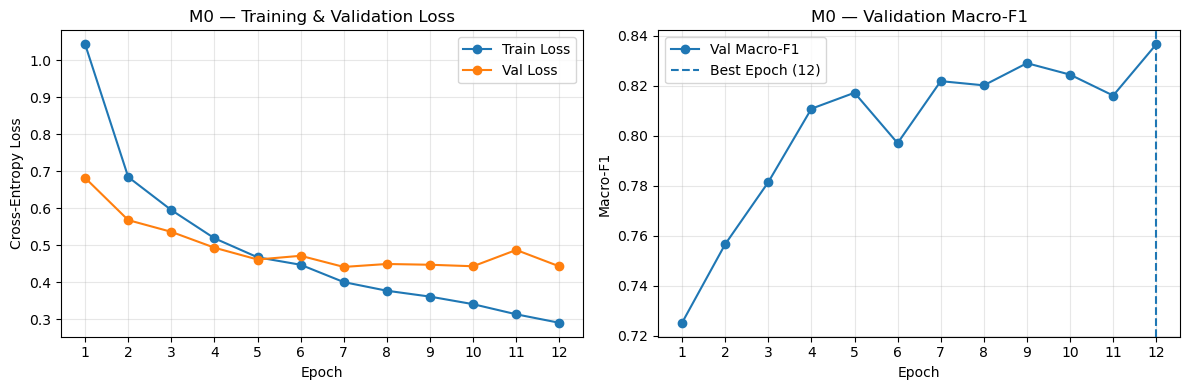

M0: Saved training history and learning curves.


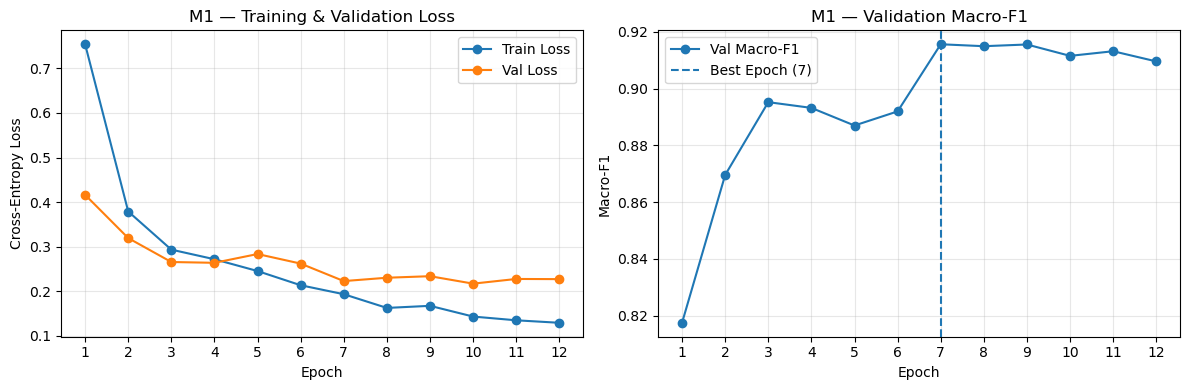

M1: Saved training history and learning curves.


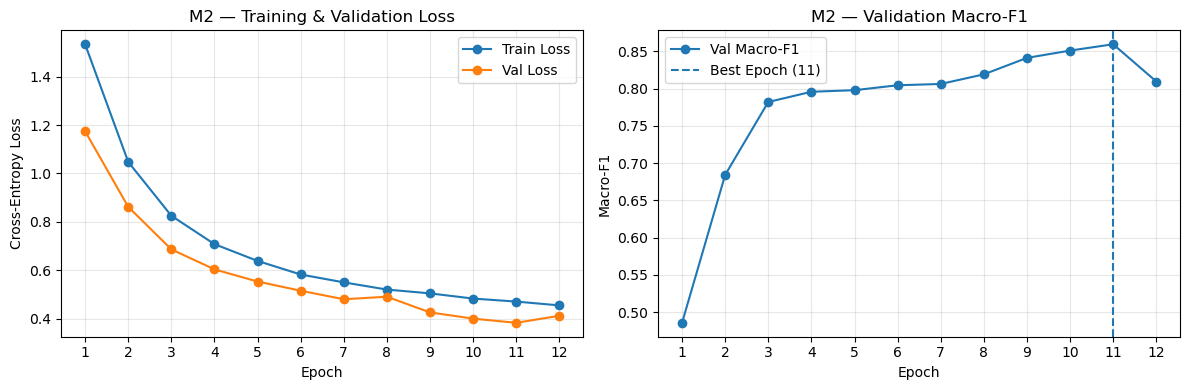

M2: Saved training history and learning curves.

BloodMNIST — Validation Summary:


,Model,Parameters,Best Epoch,Best Val Macro-F1
0,M0,636296,12,0.8366
1,M1,44680,7,0.9156
2,M2,20104,11,0.8596


In [36]:
# Prepare a list to summarize the validation results of all three models.
summary_rows = []                              # Store one comparison record for M0, M1, and M2.


# Save training histories and plot learning curves for each model.
for model_name, result in training_results.items():
    history_df = result["history"]             # Retrieve the 12-epoch training history DataFrame.
    best_epoch = result["best_epoch"]          # Epoch selected by the highest validation macro-F1.

    # Save the complete training history as a CSV file.
    csv_path = cfg.results_dir / f"bloodmnist_{model_name}_history.csv"
    history_df.to_csv(csv_path, index=False)   # Save epoch metrics without the DataFrame's row index.

    # Create two plots: loss curves and validation macro-F1.
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # Arrange two plots side by side.
    epochs = history_df["epoch"]                 # Epoch numbers from 1 to 12.

    # Plot training and validation loss to examine optimization and generalization.
    axes[0].plot(epochs, history_df["train_loss"], marker="o", label="Train Loss")  # Training loss per epoch.
    axes[0].plot(epochs, history_df["val_loss"], marker="o", label="Val Loss")      # Validation loss per epoch.
    axes[0].set_title(f"{model_name} — Training & Validation Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-Entropy Loss")
    axes[0].set_xticks(epochs)                  # Display the 12 recorded epoch numbers.
    axes[0].legend()                            # Identify the training and validation curves.
    axes[0].grid(alpha=0.3)                    # Add a light grid to make trends easier to read.

    # Plot validation macro-F1 and indicate the best checkpoint epoch.
    axes[1].plot(epochs, history_df["val_macro_f1"], marker="o", label="Val Macro-F1")
    axes[1].axvline(best_epoch, linestyle="--", label=f"Best Epoch ({best_epoch})")  # Mark checkpoint selection.
    axes[1].set_title(f"{model_name} — Validation Macro-F1")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Macro-F1")
    axes[1].set_xticks(epochs)
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    # Save and display the learning-curve figure.
    fig.tight_layout()                         # Adjust spacing to prevent overlapping labels.
    figure_path = cfg.results_dir / f"bloodmnist_{model_name}_learning_curves.png"
    fig.savefig(figure_path, dpi=150, bbox_inches="tight")  # Export a readable PNG figure.
    plt.show()                                 # Display the figure inside the Jupyter Notebook.
    plt.close(fig)                             # Release the figure after displaying it.

    # Collect the best validation results for the model comparison table.
    summary_rows.append({
        "Model": model_name,                    # Model identifier: M0, M1, or M2.
        "Parameters": result["parameters"],    # Total trainable model parameters.
        "Best Epoch": best_epoch,              # Epoch with the highest validation macro-F1.
        "Best Val Macro-F1": result["best_val_macro_f1"]  # Best validation score across 12 epochs.
    })

    print(f"{model_name}: Saved training history and learning curves.")


# Organize the three model results into one validation comparison table.
validation_summary = pd.DataFrame(summary_rows)  # One row per model, with four comparison columns.

print("\nBloodMNIST — Validation Summary:")
display(validation_summary.round({"Best Val Macro-F1": 4}))  # Display F1 scores to four decimal places.


#### 4.2 — Learning Curves & Validation Performance: Results & Interpretation

**Implementation & Verification:**

- Successfully generated learning-curve figures for M0, M1, and M2, showing training/validation loss and validation macro-F1 across all 12 epochs.  

- Saved three CSV training histories and three PNG figures, and created a validation summary comparing model performance and trainable parameter counts.  

- Marked each model's best checkpoint epoch based on validation macro-F1.

**Results & Key Observations:**

- **M0 (MLP):** Training loss decreased consistently, while validation loss largely plateaued after epoch 5 and fluctuated thereafter. Validation macro-F1 improved overall, reaching its highest value (0.8366) at epoch 12. The widening train–validation loss gap suggests possible overfitting.

- **M1 (CNN + Flatten):** Training loss decreased substantially, while validation loss improved early and later fluctuated. Validation macro-F1 reached 0.9156 at epoch 7 and remained above 0.90 through epoch 12. The widening loss gap suggests possible overfitting despite strong validation classification performance.

- **M2 (CNN + GAP):** Training and validation losses generally decreased throughout training. Validation macro-F1 improved from 0.4855 to a maximum of 0.8596 at epoch 11 before declining to 0.8096 at epoch 12. The loss curves show continued learning without pronounced divergence.

- **Parameter Efficiency:** M2 used 20,104 trainable parameters compared with M1's 44,680, representing a 55.0% reduction. However, its best validation macro-F1 was 0.0560 (5.60 percentage points) lower than M1's.

**Interpretation:**

M1 achieved the strongest validation classification performance, whereas M2 provided a more parameter-efficient architecture at the cost of lower validation macro-F1 in this experiment. Because M1 and M2 share the same convolutional feature-extractor design, their comparison highlights the performance–parameter trade-off associated with Flatten versus GAP classifier heads.

The learning curves suggest possible differences in overfitting and generalization behavior. However, training and validation losses are measured under different model modes (particularly for Dropout and BatchNorm), so loss gaps alone do not establish overfitting.

These single-seed results do not establish statistical significance or guarantee that the observed performance ranking will generalize. Final classification performance will be assessed using the held-out test set in Part 5.  

---  


## Part 5 — Final Test Evaluation & Simple Error Analysis

### Overview & Objectives

Evaluate the three trained BloodMNIST models (M0, M1, and M2) on the official held-out test set and perform a simple classification error analysis using M2's confusion matrix.

This part focuses on measuring final classification performance using accuracy and macro-F1, comparing the models alongside their trainable parameter counts, and identifying common misclassification patterns.

Each model is reconstructed and loaded from its best validation-selected checkpoint saved in Part 4. The official test set is evaluated once per model, without further training, hyperparameter tuning, or checkpoint selection.

### Workflow & Section Guide

- **5.1 — Test Accuracy & Macro-F1:** Reconstruct M0, M1, and M2 using their predefined architectures. Load each model's best validation-selected checkpoint, evaluate it on the official test DataLoader, and create a comparison table containing model names, trainable parameter counts, test accuracy, and test macro-F1.

- **5.2 — M2 Confusion Matrix:** Use the previously collected test predictions from M2 to calculate and visualize an eight-class confusion matrix using `confusion_matrix()` and `ConfusionMatrixDisplay()`. Identify the most noticeable misclassification patterns and briefly discuss potential classification difficulties.

### Important Objects & Their Roles

- `MLP`, `SimpleCNN`: Reconstruct the three model architectures before loading their trained weights.  

- `checkpoint_path`: Identifies the best validation-selected checkpoint saved for each model in Part 4.  

- `torch.load()`, `model.load_state_dict()`: Load the saved model parameters and BatchNorm buffers for final evaluation.  

- `test_loader`: Provides the official held-out test images and labels using the preprocessing established in Part 1.  

- `evaluate()`: Computes dataset-level cross-entropy loss, accuracy, macro-F1, and true/predicted labels without updating model parameters.  

- `count_parameters()`: Reports trainable parameter counts for architectural comparison.  

- `test_summary`: Stores final test accuracy, macro-F1, and parameter counts for all three models.  

- `confusion_matrix()`, `ConfusionMatrixDisplay()`: Calculate and visualize M2's classification errors across the eight blood cell classes.

### Expected Outcomes & Role in the Experiment

Three independently trained models evaluated using their best validation-selected checkpoints:

| Model | Test Dataset | Evaluation Metrics |
|---|---|---|
| **M0 — MLP Baseline** | Official BloodMNIST test split | Accuracy, Macro-F1 |
| **M1 — CNN + BN + Flatten** | Official BloodMNIST test split | Accuracy, Macro-F1 |
| **M2 — CNN + BN + GAP** | Official BloodMNIST test split | Accuracy, Macro-F1 |

Expected outputs:

- **3 final test evaluations:** One evaluation per model using its previously selected best checkpoint.  

- **1 test comparison table:** A three-row DataFrame containing model names, trainable parameter counts, test accuracy, and test macro-F1.  

- **1 confusion matrix figure:** An eight-class confusion matrix for M2, showing correct classifications and misclassification patterns.  

- **Brief error analysis:** Observations identifying blood cell classes that M2 frequently confuses, if such patterns are present.

All models use the same official test split and training-derived RGB normalization statistics. No model parameters are updated during evaluation.

**Important Distinction:** Best checkpoints were selected exclusively using validation macro-F1 in Part 4. Test results are used only for final performance reporting and error analysis. Model architectures, random seed, learning rate, training epochs, and checkpoint choices remain unchanged after inspecting test performance.

The resulting test metrics and M2 confusion matrix provide the empirical evidence for the architectural comparisons, performance–parameter trade-offs, and conclusions presented in Part 6.

---


### 5.1 — Final Test Evaluation: Accuracy & Macro-F1

**Objective:** Evaluate the three trained BloodMNIST models (M0, M1, and M2) on the official held-out test set using their best validation-selected checkpoints.

**Purpose:** Assess final classification performance on unseen data and compare the three architectures using accuracy, macro-F1, and trainable parameter counts.

**Procedure:** 

1. Reconstruct the predefined M0, M1, and M2 architectures without training or custom weight reinitialization.  

2. Load each model's best validation-selected checkpoint from the `results/` directory.  

3. Move the restored model to the selected computation device.  

4. Call `evaluate()` once per model on the official test DataLoader to calculate test accuracy and macro-F1.  

5. Create a pandas DataFrame comparing the test metrics and trainable parameter counts of all three models.  

6. Retain M2's true labels and predictions for the confusion matrix in Section 5.2.

**Expected Results:**
- Three models successfully restored from their best validation-selected checkpoints.  

- One final test evaluation per model.  

- A three-row comparison table containing model names, trainable parameter counts, test accuracy, and test macro-F1.  

- M2's complete test labels and predictions available for error analysis.

**Important Distinction:** The test set is used only for final evaluation. No model training, hyperparameter tuning, weight reinitialization, or checkpoint reselection is performed based on test results.


In [ ]:
# Prepare storage for the final test comparison and M2 confusion matrix.
test_rows = []                                  # Store one test-result record for each of the three models.
model_names = ["M0", "M1", "M2"]                # Evaluate exactly the three predefined architectures.


# Evaluate each model using its best validation-selected checkpoint.
for model_name in model_names:

    # Reconstruct the model architecture without retraining or custom reinitialization.
    if model_name == "M0":
        model = MLP(dropout_p=cfg.dropout)      # M0: two-hidden-layer MLP baseline.
    elif model_name == "M1":
        model = SimpleCNN(head="flatten", dropout_p=cfg.dropout)  # M1: CNN with Flatten head.
    else:
        model = SimpleCNN(head="gap", dropout_p=cfg.dropout)      # M2: CNN with GAP head.

    # Load the saved model weights and buffers from the best validation checkpoint.
    checkpoint_path = cfg.results_dir / f"bloodmnist_{model_name}_best.pt"  # Same filename used in Part 4.
    state_dict = torch.load(
        checkpoint_path,                       # Read the selected checkpoint from the shared results folder.
        map_location="cpu",                    # Load onto CPU first for compatibility across devices.
        weights_only=True                      # Load model weights and buffers without arbitrary Python objects.
    )
    model.load_state_dict(state_dict)          # Restore the trained parameters and BatchNorm running statistics.
    model = model.to(device)                   # Move the restored model to CUDA, MPS, or CPU.

    # Evaluate the complete official test set without updating model parameters.
    test_results = evaluate(
        model,                                 # Model restored from its best validation checkpoint.
        test_loader,                           # Official held-out BloodMNIST test DataLoader.
        criterion,                             # Shared unweighted CrossEntropyLoss.
        device                                 # Selected computation device.
    )

    # Store final test metrics and trainable parameter counts for comparison.
    test_rows.append({
        "Model": model_name,                    # Model identifier: M0, M1, or M2.
        "Parameters": count_parameters(model), # Total trainable weights and biases in this architecture.
        "Test Accuracy": test_results["accuracy"],  # Fraction of correctly classified test images.
        "Test Macro-F1": test_results["macro_f1"]    # Average F1 across the eight blood cell classes.
    })

    # Keep M2 predictions for the confusion matrix without evaluating M2 again.
    if model_name == "M2":
        m2_y_true = test_results["y_true"]      # Ground-truth class IDs for all test images.
        m2_y_pred = test_results["y_pred"]      # M2 predicted class IDs for the same images.

    # Display the final test metrics for the current model.
    print(f"{model_name} — Test Accuracy: {test_results['accuracy']:.4f} | "
          f"Test Macro-F1: {test_results['macro_f1']:.4f}")


# Organize the final test metrics into a three-model comparison table.
test_summary = pd.DataFrame(test_rows)         # Convert the list of model results into a pandas DataFrame.

print("\nBloodMNIST — Final Test Summary:")
display(test_summary.round(4))                 # Display test accuracy and macro-F1 to four decimal places.


M0 — Test Accuracy: 0.8381 | Test Macro-F1: 0.8150
M1 — Test Accuracy: 0.9152 | Test Macro-F1: 0.9051
M2 — Test Accuracy: 0.8702 | Test Macro-F1: 0.8452

BloodMNIST — Final Test Summary:


,Model,Parameters,Test Accuracy,Test Macro-F1
0,M0,636296,0.8381,0.8150
1,M1,44680,0.9152,0.9051
2,M2,20104,0.8702,0.8452


#### 5.1 — Final Test Evaluation: Results & Interpretation

**Implementation & Verification:**

- Successfully restored M0, M1, and M2 from their best validation-selected checkpoints and evaluated each model once on the official held-out test set.  

- Computed test accuracy and macro-F1 for all three models without updating model parameters.

**Results & Key Observations:**

| Model | Trainable Parameters | Test Accuracy | Test Macro-F1 |
|---|---:|---:|---:|
| M0 — MLP | 636,296 | 0.8381 | 0.8150 |
| M1 — CNN + BN + Flatten | 44,680 | **0.9152** | **0.9051** |
| M2 — CNN + BN + GAP | 20,104 | 0.8702 | 0.8452 |

- **M0 (MLP):** Achieved the lowest test macro-F1 (0.8150) despite having the largest number of trainable parameters.  

- **M1 (CNN + Flatten):** Achieved the highest test accuracy (0.9152) and macro-F1 (0.9051), outperforming both M0 and M2.  

- **M2 (CNN + GAP):** Achieved a test macro-F1 of 0.8452, exceeding M0 but remaining 0.0599 below M1. M2 used approximately 55.0% fewer trainable parameters than M1.

**Interpretation:**

Both CNN models outperformed the MLP baseline on the held-out test set, suggesting an advantage for the CNN architectures in this experiment. However, differences in BatchNorm, model capacity, and architecture prevent attributing these improvements solely to convolution.

M1 achieved the strongest test classification performance, while M2 offered greater parameter efficiency at the cost of lower macro-F1. The test results preserve the validation performance ranking (M1 > M2 > M0).

These single-seed results do not establish statistical significance or demonstrate that Flatten universally outperforms GAP. M2's classification errors will be examined further using a confusion matrix in Section 5.2.

---  


### 5.2 — M2 Confusion Matrix & Simple Error Analysis

**Objective:** Visualize the confusion matrix of M2 on the official BloodMNIST test set and identify its most noticeable classification errors.

**Purpose:** Examine how M2's predictions are distributed across the eight blood cell classes and identify classes that are more frequently misclassified.

**Procedure:** 

1. Reuse M2's true labels (`m2_y_true`) and predictions (`m2_y_pred`) collected in Section 5.1 without running another test evaluation.  

2. Compute the eight-class confusion matrix using `confusion_matrix()`.  

3. Visualize the confusion matrix using `ConfusionMatrixDisplay()`, with true classes on the rows and predicted classes on the columns.  

4. Save the confusion matrix figure as a PNG file in the `results/` directory.  

5. Identify the most frequent misclassification pair and the class with the lowest recall.

**Expected Results:** 

- One 8 × 8 confusion matrix showing M2's predictions for all 3,421 test images.  

- One saved PNG figure with labeled blood cell classes.  

- A brief summary of the most noticeable classification errors.

**Important Distinction:** The confusion matrix uses predictions already obtained during final test evaluation. This section performs descriptive error analysis only; no model retraining, hyperparameter tuning, or checkpoint reselection is allowed.


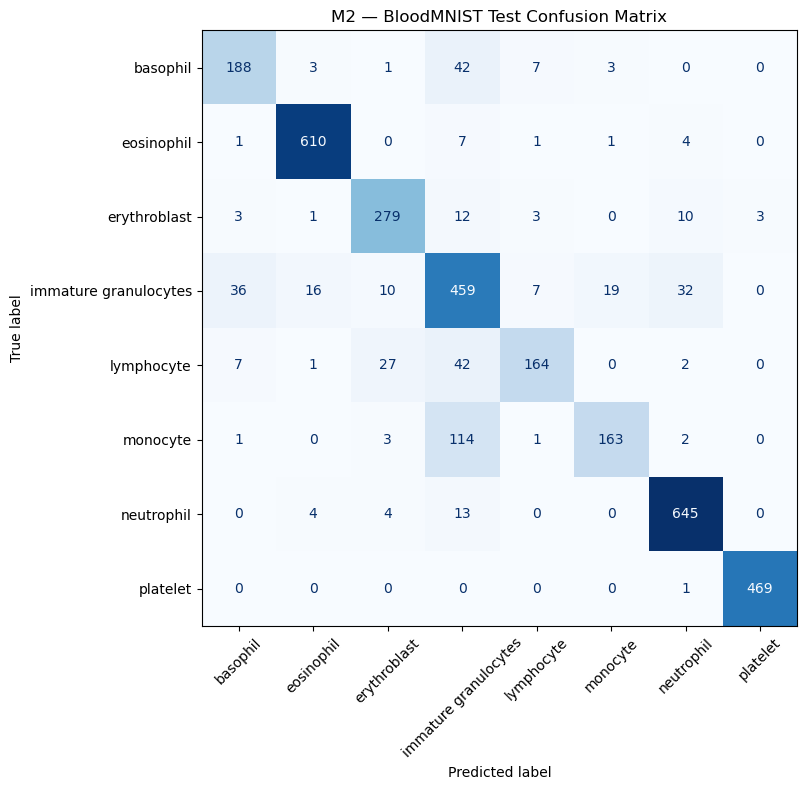

Total test images: 3421
Correct predictions: 2977
Incorrect predictions: 444

Most frequent misclassification:
  True class: monocyte
  Predicted as: immature granulocytes
  Number of errors: 114

Class with lowest recall:
  Class: monocyte
  Recall: 0.5739


In [ ]:
# Import the scikit-learn tool for displaying a confusion matrix.
from sklearn.metrics import ConfusionMatrixDisplay  # Visualize true versus predicted class labels.


# Prepare class IDs and readable blood cell names.
class_ids = list(range(len(info["label"])))  # Get class IDs 0–7 from BloodMNIST metadata.
class_names = [
    info["label"][str(i)].split("(")[0].strip() for i in class_ids
]  # Use official class names; shorten the long immature granulocytes label.



# Calculate the confusion matrix using M2 predictions collected in Section 5.1.
cm = confusion_matrix(
    m2_y_true,                            # Actual class labels from the official test set.
    m2_y_pred,                            # Class labels predicted by the selected M2 checkpoint.
    labels=class_ids                      # Keep all eight classes in their predefined numerical order.
)

assert cm.shape == (len(class_ids), len(class_ids))  # One row and column per blood cell class.
assert cm.sum() == len(test_dataset)                 # Every test image is counted exactly once.

# Display the confusion matrix with true classes on rows and predicted classes on columns.
fig, ax = plt.subplots(figsize=(11, 8))  # Create one figure with enough space for eight class labels.

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,                 # Use the 8×8 matrix of classification counts.
    display_labels=class_names            # Show readable blood cell names instead of numerical class IDs.
)

disp.plot(
    ax=ax,                               
    cmap="Blues",                        
    values_format="d",                   # Display integer counts inside each matrix cell.
    xticks_rotation=45,                  # Rotate predicted class names to prevent overlapping.
    colorbar=False                       # Omit the colorbar to keep the figure simple.
)

ax.set_title("M2 — BloodMNIST Test Confusion Matrix")
fig.tight_layout()                       # Adjust spacing to keep titles and class names visible.

# Save the confusion matrix and display it in the notebook.
figure_path = cfg.results_dir / "bloodmnist_M2_confusion_matrix.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")  # Save a readable PNG for the research report.
plt.show()                             # Display the confusion matrix in Jupyter Notebook.
plt.close(fig)                          # Close the figure after displaying it.


# Summarize correct predictions and classification errors.
correct_predictions = np.trace(cm)      # Sum the diagonal: images classified correctly.
total_predictions = cm.sum()            # Total number of evaluated test images.
total_errors = total_predictions - correct_predictions  # Count all incorrect predictions.

print("Total test images:", total_predictions)
print("Correct predictions:", correct_predictions)
print("Incorrect predictions:", total_errors)


# Identify the most frequent incorrect true-to-predicted class pair.
error_matrix = cm.copy()                # Copy the confusion matrix to preserve the original counts.
np.fill_diagonal(error_matrix, 0)       # Exclude correct predictions from the error analysis.

if total_errors > 0:
    true_id, pred_id = np.unravel_index(
        error_matrix.argmax(),          # Find the position of the largest off-diagonal count.
        error_matrix.shape              # Convert that position into row and column indices.
    )

    print("\nMost frequent misclassification:")
    print("  True class:", class_names[true_id])
    print("  Predicted as:", class_names[pred_id])
    print("  Number of errors:", error_matrix[true_id, pred_id])


# Find the class with the lowest recall to account for differences in class sizes.
class_totals = cm.sum(axis=1)           # Number of true test images belonging to each class.
class_recall = np.diag(cm) / class_totals  # Recall = correctly classified / total true images.

lowest_recall_id = np.argmin(class_recall)  # Find the class with the smallest recall value.

print("\nClass with lowest recall:")
print("  Class:", class_names[lowest_recall_id])
print("  Recall:", round(class_recall[lowest_recall_id], 4))


#### 5.2 — M2 Confusion Matrix: Results & Interpretation

**Implementation & Verification:**

- Successfully generated an 8 × 8 confusion matrix using M2's previously collected test predictions, without repeating model evaluation.
- Verified that the matrix accounts for all 3,421 test images, including 2,977 correct and 444 incorrect predictions.

**Results & Key Observations:**

- **Overall Classification:** M2 correctly classified 2,977 of 3,421 test images, corresponding to a test accuracy of 0.8702.  

- **Most Frequent Misclassification:** Monocytes were most frequently misclassified as immature granulocytes, with 114 such errors out of 284 true monocyte images (40.1%).  

- **Lowest Class Recall:** Monocytes had the lowest recall (0.5739), with only 163 of 284 images correctly identified.  

- **Other Misclassifications:** Basophils and lymphocytes were each misclassified as immature granulocytes 42 times.  

- **Strong Class Recognition:** Platelets (469/470 correct) and eosinophils (610/624 correct) showed relatively high recognition rates.

**Interpretation:**

M2 demonstrated uneven classification performance across the eight blood cell classes. Monocytes were particularly difficult to identify, with a substantial proportion predicted as immature granulocytes. In contrast, platelets and eosinophils were classified with high recall.

These results illustrate why macro-F1 is useful alongside overall accuracy: strong performance on several classes can coexist with substantially weaker recognition of another class.

**Limitations:** The confusion matrix identifies error patterns but does not establish their underlying causes. Determining whether these errors arise from visual similarities, limited image resolution, or other factors would require further analysis. No model adjustments are made based on these test results.  

---  


## Part 6 — Results, Discussion & Conclusion

### Overview & Objectives

Synthesize the experimental findings from BloodMNIST classification and evaluate the performance–parameter trade-offs among the three architectures: M0 (MLP), M1 (CNN + BatchNorm + Flatten), and M2 (CNN + BatchNorm + GAP).

This part addresses two research questions:

1. **RQ1 — MLP vs. CNN:** How do the MLP baseline and CNN architectures compare in classification performance and parameter efficiency?  

2. **RQ2 — Flatten vs. GAP:** How does replacing Flatten with Global Average Pooling affect classification performance and the number of trainable parameters?

The discussion integrates validation results, held-out test performance, learning curves, and model parameter counts. Conclusions are limited to the evidence obtained from the predefined single-seed experiment.

### Workflow & Section Guide

- **6.1 — Answer RQ1 & RQ2:** Consolidate the results of M0, M1, and M2 into a comparison table containing trainable parameters, validation macro-F1, test accuracy, and test macro-F1. Answer both research questions using the observed performance differences and the 55.0% parameter reduction achieved by M2 relative to M1.

- **6.2 — Limitations & Conclusion:** Discuss the methodological limitations of the single-seed experiment, architectural differences, 28 × 28 image resolution, fixed learning rate, and limited clinical validation. Summarize the principal findings and distinguish experimental observations from broader claims about model effectiveness.

### Important Evidence & Its Role

- **Model architectures and parameter counts (Part 2):** Establish the structural differences and parameter efficiency of M0, M1, and M2.  

- **Validation results and learning curves (Part 4):** Provide evidence of training behavior, validation performance, and best-checkpoint selection.  

- **Final test results (Section 5.1):** Provide held-out test accuracy and macro-F1 for comparing the three architectures.  

- **M2 confusion matrix (Section 5.2):** Illustrates class-specific recognition difficulties and the limitations of overall accuracy as a standalone metric.

### Expected Outcomes & Role in the Experiment

A concise, evidence-based discussion containing:

- **One consolidated comparison table:** Model architecture, trainable parameters, best validation macro-F1, test accuracy, and test macro-F1.  

- **RQ1 — MLP vs. CNN:** A comparison of classification performance and model complexity, acknowledging that architectural differences extend beyond convolution alone.  

- **RQ2 — Flatten vs. GAP:** An evaluation of the observed classification-performance trade-off associated with M2's 55.0% reduction in trainable parameters relative to M1.  

- **Limitations:** A discussion of single-seed variability, architectural confounding, low image resolution, fixed training settings, and the absence of clinical validation.  

- **Conclusion:** A summary of the principal findings, supported by the reported validation and held-out test results.

This study is intended as an educational comparison of MLP and CNN architectures rather than a statistically conclusive benchmark or clinically validated classification system.

The final deliverables are a documented Jupyter Notebook and a GitHub README summarizing the project design, methods, and findings. A short technical report (2–3 pages) is optional. No additional experiments, hypothesis testing, or extensive literature review are required.

---


### 6.1 — Answer RQ1 & RQ2

**Objective:** Compare the classification performance and trainable parameter counts of M0, M1, and M2 using the completed validation and test results.

#### Experimental Results Summary

The table below summarizes the three models evaluated under the shared experimental protocol: seed 42, Adam optimizer (learning rate = 0.001), batch size 128, and 12 training epochs. Each model was evaluated using its best validation macro-F1 checkpoint.

| Model | Trainable Parameters | Best Val Macro-F1 | Test Accuracy | Test Macro-F1 |
|---|---:|---:|---:|---:|
| M0 — MLP | 636,296 | 0.8366 | 0.8381 | 0.8150 |
| M1 — CNN + BN + Flatten | 44,680 | **0.9156** | **0.9152** | **0.9051** |
| M2 — CNN + BN + GAP | 20,104 | 0.8596 | 0.8702 | 0.8452 |

The performance ranking was consistent across validation and test macro-F1: **M1 > M2 > M0**.

#### RQ1 — How Do MLP and CNN Architectures Compare?

**Results & Key Observations:**

- M1 achieved a test macro-F1 of 0.9051, outperforming M0 (0.8150) by 0.0901, or 9.01 percentage points.  

- M2 achieved a test macro-F1 of 0.8452, exceeding M0 by 0.0302, or 3.02 percentage points.  

- Both CNN models achieved higher test accuracy and macro-F1 than M0 despite using substantially fewer trainable parameters.

**Interpretation:**

The CNN architectures performed better than the MLP baseline in this experiment. Unlike M0, which flattens the input images before classification, M1 and M2 use convolutional layers to extract spatial features.

These results suggest that the CNN designs are better suited to this BloodMNIST classification task under the tested settings. However, the models also differ in Batch Normalization, parameter counts, and overall architecture. Therefore, the performance improvements cannot be attributed solely to convolution.

#### RQ2 — How Does Replacing Flatten with GAP Affect Performance and Parameter Efficiency?

**Results & Key Observations:**

- M1 and M2 use the same two-block CNN feature-extractor architecture but different classifier heads.  

- M1 uses Flatten to convert the final feature maps into 3,136 classifier input features, while M2 uses GAP to reduce them to 64 features.  

- Replacing Flatten with GAP reduced the total trainable parameters from 44,680 (M1) to 20,104 (M2), a reduction of **24,576 parameters (55.0%)**.  

- M1 achieved a higher test macro-F1 (0.9051 versus 0.8452) and test accuracy (0.9152 versus 0.8702).  

- M2's test macro-F1 was 0.0599 (5.99 percentage points) lower than M1's.

**Interpretation:**

GAP substantially reduced the number of trainable parameters, but M2 achieved lower classification performance than M1 in this experiment.

M1 provided better test accuracy and macro-F1, while M2 offered a smaller architecture. This demonstrates a performance–parameter trade-off between the two classifier heads.

Because M1 and M2 were trained independently using a single random seed, these results describe the observed differences in this experiment rather than a universal advantage of Flatten over GAP.

#### Overall Findings

The results answer both research questions:

1. **RQ1:** Both CNN models outperformed the MLP baseline on BloodMNIST under the shared training protocol.  

2. **RQ2:** GAP reduced trainable parameters by 55.0% compared with Flatten, but resulted in lower test classification performance in this experiment.

M1 achieved the strongest classification performance, whereas M2 used the fewest trainable parameters. These findings illustrate how architectural choices can affect both model performance and parameter efficiency.

The methodological limitations and final conclusion are discussed in Section 6.2.  

---  


### 6.2 — Limitations & Conclusion

#### Limitations

This study has several limitations:

1. **Single Random Seed:** Each model was trained only once using seed 42. The results do not measure performance variability across different random initializations or establish statistical significance.

2. **Architectural Differences:** M0 differs from M1 and M2 in several aspects, including convolutional layers, Batch Normalization, and parameter counts. Therefore, performance differences between the MLP and CNN models cannot be attributed solely to convolution.

3. **Low Image Resolution:** BloodMNIST images have a resolution of 28 × 28 pixels, which may limit the fine cellular details available for classification. The findings may not directly generalize to higher-resolution biomedical images.

4. **Fixed Training Settings:** All models used the same Adam learning rate (0.001), batch size (128), and 12 training epochs, without data augmentation or hyperparameter tuning. This provides a consistent experimental protocol but does not guarantee optimal performance for each architecture.

5. **Limited Clinical Applicability:** The experiment evaluates classification performance on the BloodMNIST benchmark. It does not establish reliability on real-world clinical data or suitability for medical diagnosis.

#### Conclusion

This project compared an MLP baseline (M0) and two CNN architectures (M1 and M2) for eight-class blood cell classification using BloodMNIST.

Both CNN models achieved higher test accuracy and macro-F1 than the MLP baseline. M1 (CNN + BatchNorm + Flatten) achieved the highest test macro-F1 of **0.9051**, compared with **0.8452** for M2 (CNN + BatchNorm + GAP) and **0.8150** for M0.

Replacing Flatten with GAP reduced M2's trainable parameters by **55.0%** relative to M1, but also resulted in lower classification performance in this experiment.

The results demonstrate that model architecture and classifier-head design can influence both classification performance and parameter efficiency. M1 provided the strongest test performance, while M2 offered a smaller model with fewer trainable parameters.

Overall, this study provides a practical comparison of MLP and CNN architectures and demonstrates the application of PyTorch training, model evaluation, and basic error analysis to biomedical image classification. The findings are limited to the predefined experimental setting and should not be interpreted as general conclusions about CNN architectures or clinical performance.